# Task 3 — Multimodal Clustering: Jenis Material dari Citra Mikrostruktur + Spektrum Komposisi

**Proyek UTS Deep Learning:** *Hands-on Deep Learning: Classification, Regression, and Clustering*
**Notebook:** `task3_multimodal_clustering.ipynb` (satu file untuk **Google Colab**: *Runtime → Run all*, aktifkan GPU: *Runtime → Change runtime type → T4 GPU*)
**Reproduksi satu perintah:** *Run all* di Colab, atau `jupyter nbconvert --to notebook --execute --inplace task3_multimodal_clustering.ipynb` (seed dan versi library dicetak di Section 2).

---

# SECTION 1 — Project Overview

## Tujuan clustering
Mengelompokkan **36.000 sampel material** menjadi jenis-jenis material **tanpa label**, memakai dua modality yang dipasangkan per sampel:
1. **Citra mikrostruktur** (64×64, dari mikroskop M1 atau M2).
2. **Spektrum komposisi** (128 kanal).

Hasil dinilai dosen dengan **Adjusted Rand Index (ARI)** terhadap jenis material sebenarnya (disimpan dosen, tidak dibagikan). Nomor cluster boleh bebas. Label tersembunyi **tidak** dipakai untuk apa pun di notebook ini.

## Mengapa multimodal?
Satu modality sering tidak cukup membedakan semua jenis material: dua jenis bisa punya spektrum hampir sama tetapi mikrostruktur berbeda, atau sebaliknya. Pendekatan multimodal mempelajari **representasi (embedding) per modality**, lalu **menggabungkan** keduanya (*fusion*) sebelum clustering, sehingga cluster memanfaatkan informasi yang saling melengkapi. Notebook ini juga menunjukkan **apa yang hilang bila hanya satu modality dipakai**.

## Pembagian kontribusi
| Bagian | Penanggung jawab |
|---|---|
| EDA gambar, preprocessing gambar, *image representation learning*, **menghasilkan image embedding** | **Anggota 1** |
| EDA spektrum, preprocessing spektrum, **spectrum representation learning**, **multimodal fusion**, **clustering (KMeans/GMM + DEC)**, pemilihan jumlah cluster, UMAP/t-SNE, evaluasi, analisis | **Anggota 2** |

> Bagian gambar **bukan** hasil kerja Anggota 2: notebook ini hanya **memuat** image embedding dari Anggota 1 (Section 6) dan hanya menampilkan contoh gambar sebagai konteks (Section 4A).

## Alur metode
1. **EDA & preprocessing spektrum** — buang spike, koreksi baseline, normalisasi per sampel (tanpa label, tanpa statistik global, jadi tanpa kebocoran).
2. **Spectrum representation learning** — *autoencoder* vs *contrastive encoder* dengan augmentasi yang meniru distorsi spektrum (geseran, baseline, spike, noise), dibandingkan dengan PCA.
3. **Integrasi image embedding Anggota 1** dan **fusion** (beberapa strategi).
4. **Clustering:** KMeans/GMM dan **Deep Embedded Clustering (DEC)**.
5. **Jumlah cluster** dengan beberapa kriteria, **UMAP/t-SNE**, evaluasi (ARI bila referensi tersedia; metrik internal dan kestabilan), analisis, ekspor `cluster.csv`.

# SECTION 2 — Library Installation & Import

In [1]:
# Instalasi hanya jika library belum ada (di Google Colab kebanyakan sudah terpasang).
import importlib, subprocess, sys

for pkg, mod in [("torch", "torch"), ("scikit-learn", "sklearn"), ("pandas", "pandas"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn"), ("umap-learn", "umap")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        print(f"Memasang {pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

d:\TELKOM\Semester 7\DL\UTS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os, re, sys, json, time, random, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.model_selection import cross_val_predict
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score, r2_score)
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from scipy.stats import chi2_contingency

import torch
import torch.nn as nn
import torch.nn.functional as F
import umap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 100

# ---- Random seed (reproducibility) ----
SEED = 42
def set_seed(seed: int = SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# ---- GPU configuration ----
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Versi   :", f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | torch {torch.__version__} | seed {SEED}")
print("Device  :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU (training DL jauh lebih lambat; aktifkan GPU: Runtime > Change runtime type > T4 GPU, lalu Run all ulang)")

Versi   : python 3.11.9 | numpy 2.4.6 | pandas 3.1.1 | scikit-learn 1.9.1 | torch 2.15.0+cpu | seed 42
Device  : cpu | CPU (training DL jauh lebih lambat; aktifkan GPU: Runtime > Change runtime type > T4 GPU, lalu Run all ulang)


# SECTION 3 — Configuration & Dataset Loading

**Data diunggah manual dari PC** (default `USE_GOOGLE_DRIVE = False`). Saat Section 3 dijalankan di Colab, muncul dialog unggah. Pilih `clustering_meta.csv` **dan salah satu** dari:
* `clustering_tanpa_gambar.npz` (±8 MB, **cukup untuk bagian Anggota 2**; contoh gambar di Section 4A dilewati), atau
* `clustering.npz` (±150 MB, berisi gambar; unggah lebih lama).

Hanya array `spektrum` yang dibaca ke memori untuk pemrosesan. Berkas di runtime Colab **hilang bila runtime di-reset**, jadi di akhir (Section 15) hasil antara (embedding, bobot model, assignment) ikut diunduh sebagai `task3_outputs.zip` sebagai cadangan. Ingin pakai Google Drive? Set `USE_GOOGLE_DRIVE = True`.

In [5]:
# ---------------- KONFIGURASI (VERSI LOKAL) ----------------
USE_GOOGLE_DRIVE = False
ASK_UPLOAD_IMG_EMB = False
IN_COLAB = False

CANDIDATE_DIRS = ["../dataset", "dataset", "..", "."]
NPZ_NAMES      = ["clustering.npz", "clustering_tanpa_gambar.npz"]
META_FILE      = "clustering_meta.csv"
N_EXPECTED     = 36000

OUTPUT_DIR = Path(".")         # Tidak membuat folder outputs baru; simpan langsung di direktori aktif
RETRAIN = False                # True: abaikan cache bobot/embedding dan latih ulang semua model

# --- Preprocessing spektrum ---
SPIKE_MAD  = 7.0               # spike jika |selisih ke rata-rata tetangga| > 7 x MAD
BASE_DEG   = 3                 # derajat polinomial baseline
BASE_ITERS = 60                # iterasi pemotongan baseline (ModPoly)

# --- Representasi spektrum ---
EMB_DIM    = 32                # dimensi embedding spektrum
SHIFT_MAX  = 6.0               # augmentasi geser maksimum (kanal); geseran nyata kira-kira +-5 kanal
TAU        = 0.2               # temperatur NT-Xent
CL_EPOCHS, AE_EPOCHS = 60, 60
BATCH, LR  = 1024, 1e-3

# --- Clustering ---
K_RANGE    = list(range(2, 13))
N_INIT     = 10
N_STAB     = 5                 # ulangan resampling untuk kestabilan
DEC_LATENT, DEC_PRETRAIN_EPOCHS, DEC_EPOCHS = 10, 60, 80
DEC_TOL, DEC_GAMMA, DEC_LR = 0.001, 0.1, 5e-4

# --- Embedding gambar Anggota 1 ---
IMG_EMB_FILE = "embedding_gambar.npz"
IMG_ID_KEY, IMG_EMB_KEY = "id_sampel", "embedding"

# --- Label referensi ---
REF_LABEL_FILE = "referensi_label.csv"

In [ ]:
def find_data():
    for d in CANDIDATE_DIRS:
        for n in NPZ_NAMES:
            if (Path(d) / n).exists() and (Path(d) / META_FILE).exists():
                return Path(d), n
    return None, None

def upload_files(target_dir):
    # Dialog unggah dari PC (hanya di Colab). Nama ' (1)' yang ditambahkan Colab pada unggahan berulang dihapus.
    from google.colab import files
    target_dir = Path(target_dir); target_dir.mkdir(parents=True, exist_ok=True)
    saved = []
    for name, content in files.upload().items():
        clean = re.sub(r" \(\d+\)(?=\.[^.]+$)", "", name)
        (target_dir / clean).write_bytes(content); saved.append(clean)
    print("Tersimpan di", target_dir.resolve(), ":", saved)

DATA_DIR, NPZ_NAME = find_data()
if DATA_DIR is None and IN_COLAB:
    print(f"Dataset belum ada di runtime. Pilih dari PC: {META_FILE} + (clustering_tanpa_gambar.npz [cukup] ATAU clustering.npz):")
    upload_files("dataset"); DATA_DIR, NPZ_NAME = find_data()
assert DATA_DIR is not None, (f"{NPZ_NAMES} + {META_FILE} tidak ditemukan di {CANDIDATE_DIRS}. "
                              "Jalankan ulang cell ini dan unggah kedua berkas (Colab), atau taruh di folder dataset/.")
NPZ_PATH, META_PATH = DATA_DIR / NPZ_NAME, DATA_DIR / META_FILE
print("DATA_DIR =", DATA_DIR.resolve(), "| berkas array:", NPZ_NAME)

# ---- Struktur folder ----
for f in sorted(DATA_DIR.iterdir()):
    if f.is_file():
        print(f"   {f.name:<34s} {f.stat().st_size / 1e6:9.2f} MB")

# ---- Struktur isi npz: baca hanya header (tanpa memuat array besar) ----
def npz_info(path):
    info = {}
    with zipfile.ZipFile(path) as z:
        for name in z.namelist():
            if name.endswith(".npy"):
                with z.open(name) as fh:
                    ver = np.lib.format.read_magic(fh)
                    rd = np.lib.format.read_array_header_1_0 if ver == (1, 0) else np.lib.format.read_array_header_2_0
                    shape, _, dtype = rd(fh)
                info[name[:-4]] = (shape, np.dtype(dtype))
    return info

NPZ_INFO = npz_info(NPZ_PATH)
print("\nIsi npz:", {k: f"{v[0]} {v[1]}" for k, v in NPZ_INFO.items()})
assert "spektrum" in NPZ_INFO, f"array 'spektrum' tidak ada; kunci tersedia: {list(NPZ_INFO)}"
HAS_IMAGES = "gambar" in NPZ_INFO

meta = pd.read_csv(META_PATH)
print("\nMeta:", meta.shape, "| kolom:", list(meta.columns)); print(meta.dtypes.to_string())
print(meta.head(3).to_string(index=False))

Dataset belum ada di runtime. Pilih dari PC: clustering_meta.csv + (clustering_tanpa_gambar.npz [cukup] ATAU clustering.npz):


Saving clustering.npz to clustering.npz
Saving clustering_meta.csv to clustering_meta.csv
Tersimpan di /content/dataset : ['clustering.npz', 'clustering_meta.csv']
DATA_DIR = /content/dataset | berkas array: clustering.npz
   clustering.npz                        130.26 MB
   clustering_meta.csv                     0.60 MB

Isi npz: {'gambar': '(36000, 64, 64) uint8', 'spektrum': '(36000, 128) float16'}

Meta: (36000, 3) | kolom: ['indeks', 'id_sampel', 'mikroskop']
indeks        int64
id_sampel    object
mikroskop    object
 indeks id_sampel mikroskop
      0   S966119        M1
      1   S315633        M2
      2   S805122        M1


In [ ]:
# ---- Identifikasi ID sampel & pemeriksaan jumlah/pairing ----
N = len(meta)
IDS = meta["id_sampel"].astype(str).to_numpy()
MIC = (meta["mikroskop"].to_numpy() == "M2").astype(int)            # M1 = 0, M2 = 1

assert set(meta["mikroskop"].unique()) == {"M1", "M2"}, meta["mikroskop"].unique()
assert meta["id_sampel"].is_unique, "id_sampel tidak unik"
assert (meta["indeks"].to_numpy() == np.arange(N)).all(), "kolom 'indeks' harus = 0..N-1 (baris i meta <-> array ke-i)"
assert all(re.fullmatch(r"S\d{6}", s) for s in IDS), "format id_sampel tidak seperti S123456"
assert NPZ_INFO["spektrum"][0][0] == N, f"jumlah spektrum {NPZ_INFO['spektrum'][0][0]} != jumlah baris meta {N}"
if HAS_IMAGES:
    assert NPZ_INFO["gambar"][0][0] == N, "jumlah gambar != jumlah baris meta"
if N != N_EXPECTED:
    print(f"PERINGATAN: N = {N}, bukan {N_EXPECTED}")

print(f"N sampel = {N} | ID unik | indeks = 0..{N - 1} | M1: {int((MIC == 0).sum())}, M2: {int((MIC == 1).sum())}")
print("Pairing: baris i pada meta = gambar[i] = spektrum[i] (kunci pairing: kolom 'indeks'/urutan baris; ID = id_sampel).")

npz = np.load(NPZ_PATH)
SPEC_RAW = npz["spektrum"]                       # (N, 128) float16, hanya array ini yang dimuat ke memori
X_RAW = SPEC_RAW.astype(np.float32)
L = X_RAW.shape[1]
print(pd.DataFrame({"array": ["spektrum"] + (["gambar"] if HAS_IMAGES else []),
                    "shape": [SPEC_RAW.shape] + ([NPZ_INFO["gambar"][0]] if HAS_IMAGES else []),
                    "dtype": [str(SPEC_RAW.dtype)] + ([str(NPZ_INFO["gambar"][1])] if HAS_IMAGES else [])}).to_string(index=False))

N sampel = 36000 | ID unik | indeks = 0..35999 | M1: 21636, M2: 14364
Pairing: baris i pada meta = gambar[i] = spektrum[i] (kunci pairing: kolom 'indeks'/urutan baris; ID = id_sampel).
   array           shape   dtype
spektrum    (36000, 128) float16
  gambar (36000, 64, 64)   uint8


# SECTION 4 — Exploratory Data Analysis

## Bagian A — Image EDA
> **EDA gambar dikerjakan Anggota 1.** Contoh gambar di bawah memberi konteks; analisis lengkap (statistik, derau dan domain shift antar-mikroskop, rotasi, skala) ada pada cell 4A.1 sampai 4A.4 setelah interpretasi awal.

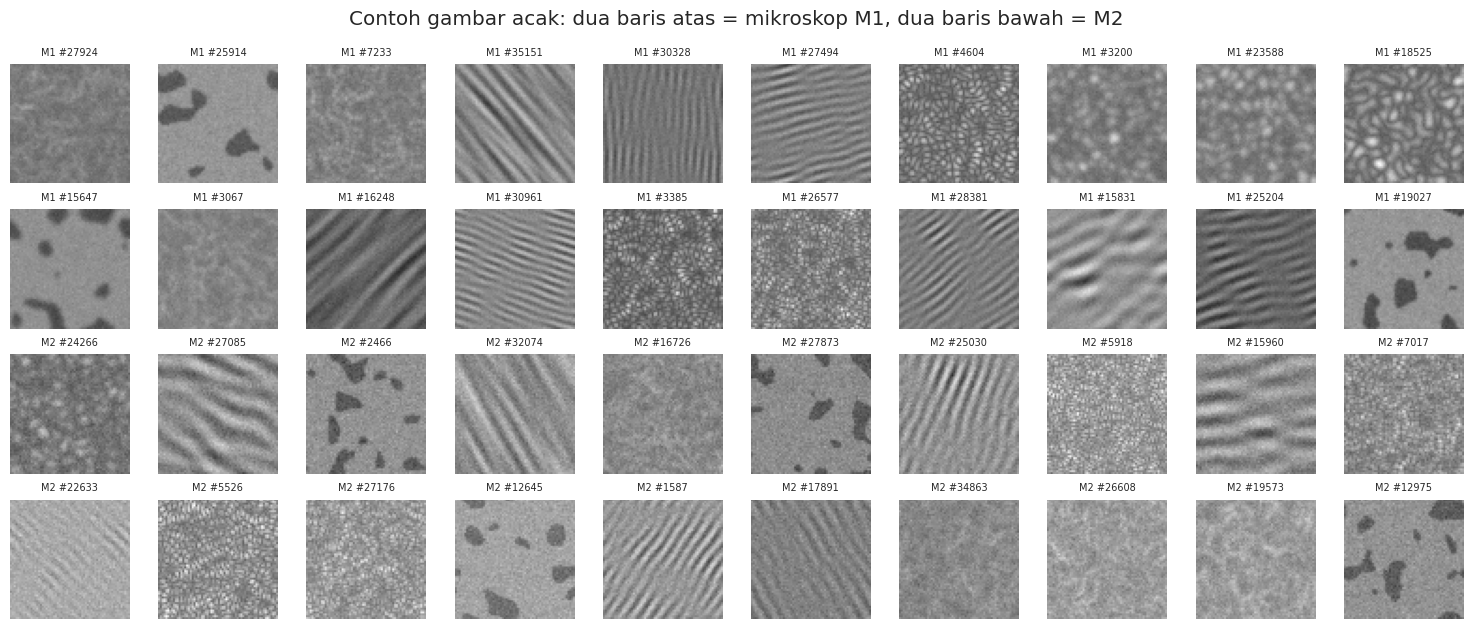

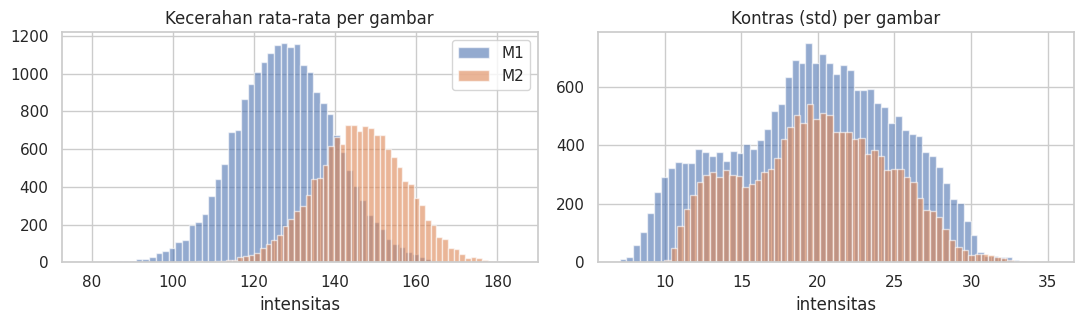

    kecerahan_rata2  kontras_rata2
M1            127.8           19.7
M2            146.1           19.9


In [ ]:
if HAS_IMAGES:
    GAMBAR = npz["gambar"]                                   # (N, 64, 64) uint8, +-150 MB
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(4, 10, figsize=(15, 6.4))
    for r, (mic_name, mic_val) in enumerate([("M1", 0), ("M2", 1)]):
        pick = rng.choice(np.where(MIC == mic_val)[0], 20, replace=False)
        for j, i in enumerate(pick):
            ax = axes[2 * r + j // 10, j % 10]; ax.imshow(GAMBAR[i], cmap="gray", vmin=0, vmax=255); ax.axis("off")
            ax.set_title(f"{mic_name} #{i}", fontsize=7)
    plt.suptitle("Contoh gambar acak: dua baris atas = mikroskop M1, dua baris bawah = M2"); plt.tight_layout(); plt.show()

    img_mean, img_std = GAMBAR.mean(axis=(1, 2)), GAMBAR.std(axis=(1, 2))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    for v, nm in [(0, "M1"), (1, "M2")]:
        ax[0].hist(img_mean[MIC == v], bins=60, alpha=.6, label=nm); ax[1].hist(img_std[MIC == v], bins=60, alpha=.6, label=nm)
    ax[0].set(title="Kecerahan rata-rata per gambar", xlabel="intensitas"); ax[1].set(title="Kontras (std) per gambar", xlabel="intensitas"); ax[0].legend()
    plt.tight_layout(); plt.show()
    print(pd.DataFrame({"kecerahan_rata2": [img_mean[MIC == 0].mean(), img_mean[MIC == 1].mean()],
                        "kontras_rata2": [img_std[MIC == 0].mean(), img_std[MIC == 1].mean()]}, index=["M1", "M2"]).round(1))
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; contoh gambar dilewati (tidak memengaruhi bagian spektrum).")

**Interpretasi (konteks; analisis mendalam oleh Anggota 1).** Perbedaan kecerahan/kontras rata-rata antara M1 dan M2 pada histogram menunjukkan adanya *domain shift* antar-mikroskop pada gambar:
fitur gambar yang peka terhadap kecerahan berisiko membuat cluster mengikuti mikroskop, bukan jenis material. Karena itu Section 13 memeriksa keterkaitan cluster akhir dengan kolom `mikroskop`.

In [ ]:
if HAS_IMAGES:
    # ---- 4A.1 Statistik dasar gambar: ukuran, saturasi, duplikat, perbedaan mikroskop ----
    G = GAMBAR.astype(np.float32)                                   # (N, 64, 64)
    g_mean, g_std = G.mean(axis=(1, 2)), G.std(axis=(1, 2))
    print(f"bentuk = {GAMBAR.shape} | dtype = {GAMBAR.dtype} | min = {GAMBAR.min()} | max = {GAMBAR.max()}")
    print(f"piksel = 0: {(GAMBAR == 0).mean() * 100:.3f}% | piksel = 255: {(GAMBAR == 255).mean() * 100:.3f}% (indikasi saturasi)")
    print(f"gambar duplikat persis: {N - len({hash(GAMBAR[i].tobytes()) for i in range(N)})} | gambar hampir konstan (std < 1): {int((g_std < 1).sum())}")

    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    for v, nm in [(0, "M1"), (1, "M2")]:
        ax[0].plot(np.bincount(GAMBAR[MIC == v].ravel(), minlength=256) / GAMBAR[MIC == v].size, label=nm)
    ax[0].set(title="Distribusi intensitas piksel", xlabel="intensitas", ylabel="proporsi"); ax[0].legend()
    mean_img = [G[MIC == v].mean(0) for v in (0, 1)]
    lo, hi = min(m.min() for m in mean_img), max(m.max() for m in mean_img)
    for k, nm in enumerate(["M1", "M2"]):
        im = ax[1 + k].imshow(mean_img[k], cmap="gray", vmin=lo, vmax=hi); ax[1 + k].set_title(f"Rata-rata semua gambar {nm}"); ax[1 + k].axis("off")
    plt.tight_layout(); plt.show()
    print(pd.DataFrame({"kecerahan_rata2": [g_mean[MIC == v].mean() for v in (0, 1)], "std_kecerahan_antar_gambar": [g_mean[MIC == v].std() for v in (0, 1)],
                        "kontras_rata2": [g_std[MIC == v].mean() for v in (0, 1)],
                        "rentang_gambar_rata2 (gradien pencahayaan)": [m.max() - m.min() for m in mean_img]}, index=["M1", "M2"]).round(2))
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; bagian ini dilewati.")

In [ ]:
if HAS_IMAGES:
    # ---- 4A.2 Derau dan domain shift antar-mikroskop ----
    from sklearn.metrics import roc_auc_score

    def noise_sigma(G, chunk=4000):
        # Sigma derau per gambar: MAD residu terhadap rata-rata 4 tetangga (white noise: var residu = 1.25 sigma^2). Ukuran relatif antar-gambar.
        out = []
        for s in range(0, len(G), chunk):
            g = G[s:s + chunk]; r = (g[:, 1:-1, 1:-1] - 0.25 * (g[:, :-2, 1:-1] + g[:, 2:, 1:-1] + g[:, 1:-1, :-2] + g[:, 1:-1, 2:])).reshape(len(g), -1)
            out.append(np.median(np.abs(r - np.median(r, axis=1, keepdims=True)), axis=1) * 1.4826 / np.sqrt(1.25))
        return np.concatenate(out)

    g_noise = noise_sigma(G)
    auc = lambda f: max(roc_auc_score(MIC, f), 1 - roc_auc_score(MIC, f))
    print(pd.DataFrame({"sigma_derau_median": [np.median(g_noise[MIC == v]) for v in (0, 1)],
                        "derau/kontras_median": [np.median(g_noise[MIC == v] / g_std[MIC == v]) for v in (0, 1)]}, index=["M1", "M2"]).round(3))
    print("AUC pemisah mikroskop per fitur tunggal (0.5 = tidak terpisah):",
          {"kecerahan": round(auc(g_mean), 3), "kontras": round(auc(g_std), 3), "derau": round(auc(g_noise), 3)})

    # PCA piksel mentah: apakah komponen terbesar adalah mikroskop/kecerahan, bukan tekstur?
    rg = np.random.default_rng(SEED); sub_pca = rg.choice(N, min(6000, N), replace=False)
    pca_px = PCA(10, random_state=SEED).fit(G[sub_pca].reshape(len(sub_pca), -1)); S_px = pca_px.transform(G[sub_pca].reshape(len(sub_pca), -1))
    print(f"PCA piksel mentah: varians PC1 = {pca_px.explained_variance_ratio_[0] * 100:.1f}% | korelasi |PC1| dengan kecerahan = {abs(np.corrcoef(S_px[:, 0], g_mean[sub_pca])[0, 1]):.3f}"
          f" | dengan mikroskop = {abs(np.corrcoef(S_px[:, 0], MIC[sub_pca])[0, 1]):.3f}")

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    for v, nm in [(0, "M1"), (1, "M2")]: ax[0].hist(g_noise[MIC == v], bins=60, alpha=.6, label=nm)
    ax[0].set(title="Estimasi sigma derau per gambar", xlabel="sigma"); ax[0].legend()
    pick = rg.choice(N, min(4000, N), replace=False); ax[1].scatter(g_mean[pick], g_noise[pick], c=MIC[pick], s=3, cmap="coolwarm", alpha=.5)
    ax[1].set(title="Kecerahan vs derau (biru = M1, merah = M2)", xlabel="kecerahan rata-rata", ylabel="sigma derau")
    ax[2].bar(range(1, 11), pca_px.explained_variance_ratio_ * 100); ax[2].set(title="PCA piksel mentah: varians per komponen (%)", xlabel="komponen")
    plt.tight_layout(); plt.show()
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; bagian ini dilewati.")

In [ ]:
if HAS_IMAGES:
    # ---- 4A.3 Rotasi: arah dominan tekstur (structure tensor) ----
    from scipy.ndimage import gaussian_filter, sobel
    from scipy.stats import chisquare

    def orientation(G, sigma=1.0, chunk=6000):
        # theta = arah gradien dominan (derajat, -90..90); koherensi 0..1 (1 = tekstur searah, mis. garis; 0 = tanpa arah)
        th, co = [], []
        for s in range(0, len(G), chunk):
            g = gaussian_filter(G[s:s + chunk], sigma=(0, sigma, sigma)); gx, gy = sobel(g, axis=2), sobel(g, axis=1)
            jxx, jyy, jxy = (gx * gx).sum((1, 2)), (gy * gy).sum((1, 2)), (gx * gy).sum((1, 2))
            th.append(np.degrees(0.5 * np.arctan2(2 * jxy, jxx - jyy))); co.append(np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-8))
        return np.concatenate(th), np.concatenate(co)

    g_theta, g_coh = orientation(G)
    COH_THR = 0.5; directional = g_coh > COH_THR
    print(f"gambar bertekstur searah (koherensi > {COH_THR}): {directional.sum()} ({directional.mean() * 100:.1f}%)")
    cnt = np.histogram(g_theta[directional], bins=12, range=(-90, 90))[0]; p_uni = chisquare(cnt).pvalue
    print(f"uji keseragaman arah dominan (chi-kuadrat, 12 bin): p = {p_uni:.3g} | rasio bin terbesar/terkecil = {cnt.max() / max(cnt.min(), 1):.2f}")
    print("Kesimpulan otomatis:", "arah dominan menyebar merata -> rotasi adalah distorsi (bukan penanda jenis)" if cnt.max() / max(cnt.min(), 1) < 1.3
          else "arah dominan TIDAK merata -> periksa apakah orientasi tertentu terkait jenis material")

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    ax[0].hist(g_coh, bins=60); ax[0].axvline(COH_THR, c="r", ls="--"); ax[0].set(title="Koherensi arah per gambar", xlabel="koherensi")
    for v, nm in [(0, "M1"), (1, "M2")]: ax[1].hist(g_theta[directional & (MIC == v)], bins=36, range=(-90, 90), alpha=.6, label=nm)
    ax[1].set(title="Arah dominan (gambar searah)", xlabel="derajat"); ax[1].legend()
    idx_dir = np.where(directional)[0][:4].tolist() + np.where(~directional)[0][:4].tolist()
    ax[2].imshow(np.hstack([G[i] for i in idx_dir[:4]] + [np.full((64, 4), 255, np.float32)] + [G[i] for i in idx_dir[4:]]), cmap="gray"); ax[2].axis("off")
    ax[2].set_title("Kiri: searah | kanan: tidak searah")
    plt.tight_layout(); plt.show()
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; bagian ini dilewati.")

In [ ]:
if HAS_IMAGES:
    # ---- 4A.4 Skala: profil daya radial (invarian rotasi) dan frekuensi spasial dominan ----
    def radial_profile(G, nb=24, chunk=4000):
        # Rata-rata |FFT|^2 per cincin frekuensi (siklus/piksel 0..0.5) setelah rata-rata gambar dikurangi. Tidak bergantung pada rotasi.
        n = G.shape[1]; rr = np.sqrt(np.fft.fftfreq(n)[:, None] ** 2 + np.fft.fftfreq(n)[None, :] ** 2)
        edges = np.linspace(0, 0.5, nb + 1); idx = np.digitize(rr, edges) - 1; masks = [idx == k for k in range(nb)]
        out = np.zeros((len(G), nb), np.float32)
        for s in range(0, len(G), chunk):
            g = G[s:s + chunk]; P = np.abs(np.fft.fft2(g - g.mean((1, 2), keepdims=True))) ** 2
            for k, m in enumerate(masks): out[s:s + chunk, k] = P[:, m].mean(1)
        return out, 0.5 * (edges[1:] + edges[:-1])

    RP, FREQ = radial_profile(G)
    f_peak = FREQ[1:][RP[:, 1:].argmax(1)]                          # frekuensi dominan (abaikan cincin DC)
    per_stripe = 1 / f_peak[directional]
    print("periode tekstur gambar searah (piksel) p5 / median / p95:", np.percentile(per_stripe, [5, 50, 95]).round(1).tolist())
    print("frekuensi dominan semua gambar (siklus/piksel) p5 / median / p95:", np.percentile(f_peak, [5, 50, 95]).round(3).tolist())

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    for v, nm in [(0, "M1"), (1, "M2")]: ax[0].loglog(FREQ, RP[MIC == v].mean(0), label=nm)
    ax[0].set(title="Profil daya radial rata-rata", xlabel="frekuensi (siklus/piksel)", ylabel="daya"); ax[0].legend()
    ax[1].hist(per_stripe, bins=40); ax[1].set(title="Periode tekstur gambar searah", xlabel="piksel")
    pick = np.random.default_rng(SEED).choice(N, min(5000, N), replace=False); ax[2].scatter(f_peak[pick], g_coh[pick], c=MIC[pick], s=3, cmap="coolwarm", alpha=.5)
    ax[2].set(title="Frekuensi dominan vs koherensi arah", xlabel="frekuensi dominan", ylabel="koherensi")
    plt.tight_layout(); plt.show()
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; bagian ini dilewati.")

**Interpretasi EDA gambar.**
1. Contoh gambar memperlihatkan beberapa keluarga tekstur: garis/lamela, bercak gelap, jaringan sel, pola labirin, butiran halus.
2. M2 lebih terang sekitar 18 level (127,8 vs 146,1) dengan kontras setara (19,7 vs 19,9), jadi offset kecerahan dibuang dengan normalisasi per gambar. Baca juga tabel derau dan AUC pada 4A.2: bila derau M2 berbeda, perbedaan itu tidak hilang oleh normalisasi dan ditangani augmentasi derau di Bagian C.
3. Dari 4A.3 dan 4A.4: bila arah dominan merata dan periode tekstur menyebar kontinu, rotasi dan skala adalah distorsi, bukan penanda jenis material, sehingga embedding dilatih agar invarian terhadap keduanya.

## Bagian B — Spectrum EDA

bentuk                                           (36000, 128)
dtype asli                                            float16
NaN                                                         0
Inf                                                         0
min                                                 -1.663086
max                                                  6.152344
rata-rata                                            0.448439
std                                                  0.406897
% nilai negatif                                      9.066536
jumlah per sampel (p1 / median / p99)    [-15.1, 57.4, 130.3]


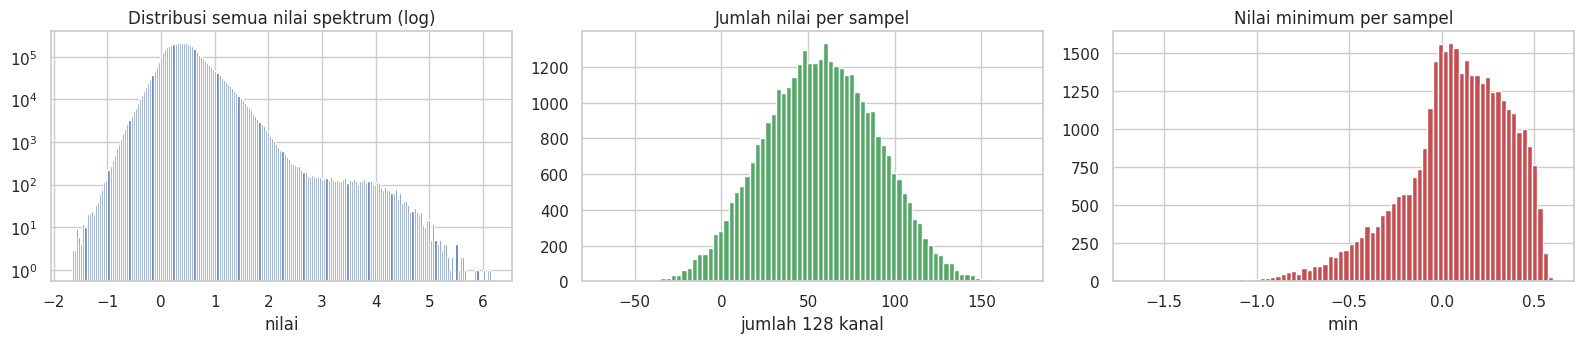

In [ ]:
# ---- 4.1 Ukuran, tipe, rentang nilai, missing ----
n_nan, n_inf = int(np.isnan(X_RAW).sum()), int(np.isinf(X_RAW).sum())
sample_sum = X_RAW.sum(1)
summary = pd.Series({
    "bentuk": str(X_RAW.shape), "dtype asli": str(SPEC_RAW.dtype), "NaN": n_nan, "Inf": n_inf,
    "min": float(X_RAW.min()), "max": float(X_RAW.max()), "rata-rata": float(X_RAW.mean()), "std": float(X_RAW.std()),
    "% nilai negatif": float((X_RAW < 0).mean() * 100),
    "jumlah per sampel (p1 / median / p99)": np.percentile(sample_sum, [1, 50, 99]).round(1).tolist()})
print(summary.to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].hist(X_RAW.ravel(), bins=200, log=True, color="#4c72b0"); ax[0].set(title="Distribusi semua nilai spektrum (log)", xlabel="nilai")
ax[1].hist(sample_sum, bins=80, color="#55a868"); ax[1].set(title="Jumlah nilai per sampel", xlabel="jumlah 128 kanal")
ax[2].hist(X_RAW.min(1), bins=80, color="#c44e52"); ax[2].set(title="Nilai minimum per sampel", xlabel="min")
plt.tight_layout(); plt.show()

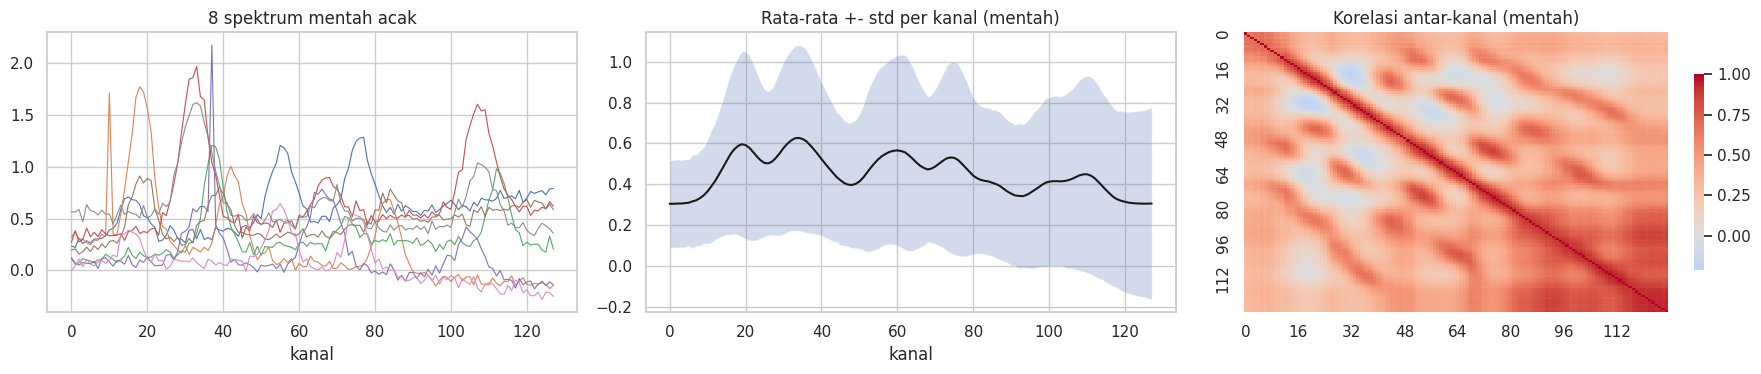

In [ ]:
# ---- 4.2 Bentuk spektrum: contoh mentah, rata-rata, dan struktur korelasi antar-kanal ----
rng = np.random.default_rng(SEED); pick = rng.choice(N, 8, replace=False)
mu, sd = X_RAW.mean(0), X_RAW.std(0)
fig, ax = plt.subplots(1, 3, figsize=(18, 3.9))
for i in pick: ax[0].plot(X_RAW[i], lw=.8)
ax[0].set(title="8 spektrum mentah acak", xlabel="kanal")
ax[1].plot(mu, "k"); ax[1].fill_between(np.arange(L), mu - sd, mu + sd, alpha=.25); ax[1].set(title="Rata-rata +- std per kanal (mentah)", xlabel="kanal")
sns.heatmap(np.corrcoef(X_RAW[::4].T), cmap="coolwarm", center=0, ax=ax[2], cbar_kws={"shrink": .7}, xticklabels=16, yticklabels=16)
ax[2].set_title("Korelasi antar-kanal (mentah)")
plt.tight_layout(); plt.show()

**Interpretasi.** Spektrum bukan derau acak: terdapat **beberapa puncak sempit** pada posisi kanal tertentu, tetapi tiap sampel tampak "terangkat" pada level dasar yang berbeda-beda
(garis dasar yang melengkung, bahkan sebagian nilai negatif), ada **lonjakan tajam satu kanal**, dan puncak tampak **bergeser** antar-sampel. Rata-rata ± std per kanal sangat lebar karena campuran jenis material
dan distorsi ini, dan korelasi antar-kanal didominasi struktur pita-diagonal (kanal bertetangga berkorelasi) ditambah pengaruh baseline.

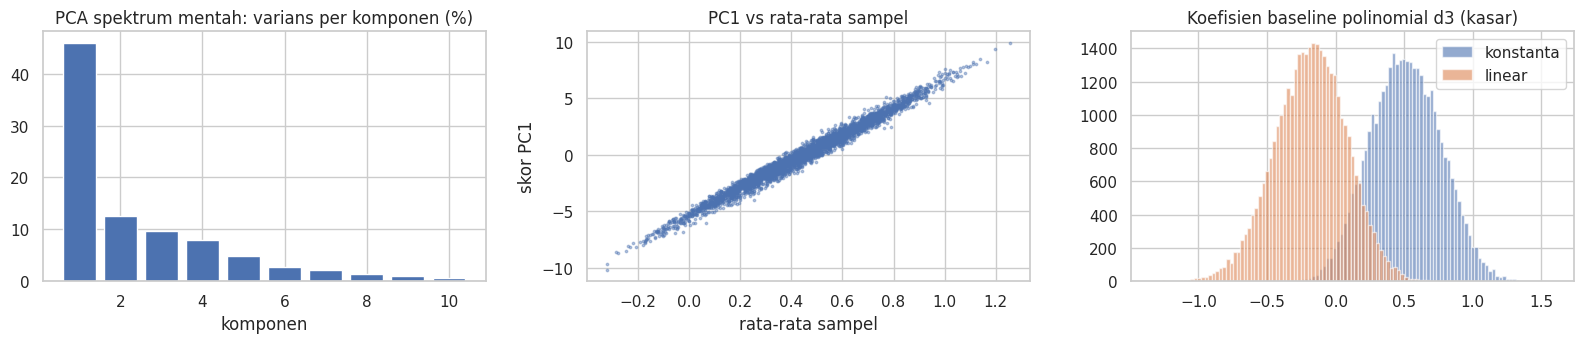

Varians PC1 = 45.9% | korelasi PC1 dengan rata-rata sampel = 0.991


In [ ]:
# ---- 4.3 Baseline: apakah komponen terbesar variasi adalah jenis material atau offset? ----
pca_raw = PCA(10, random_state=SEED).fit(X_RAW); S_raw = pca_raw.transform(X_RAW)
t_ax = np.linspace(-1, 1, L); V3 = np.vander(t_ax, 4); coef = np.linalg.lstsq(V3, X_RAW.T.astype(np.float64), rcond=None)[0]   # polinomial d3 per sampel (kasar)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].bar(range(1, 11), pca_raw.explained_variance_ratio_ * 100); ax[0].set(title="PCA spektrum mentah: varians per komponen (%)", xlabel="komponen")
ax[1].scatter(X_RAW.mean(1)[::10], S_raw[::10, 0], s=3, alpha=.4); ax[1].set(title="PC1 vs rata-rata sampel", xlabel="rata-rata sampel", ylabel="skor PC1")
ax[2].hist(coef[3], bins=80, alpha=.6, label="konstanta"); ax[2].hist(coef[2], bins=80, alpha=.6, label="linear"); ax[2].legend(); ax[2].set_title("Koefisien baseline polinomial d3 (kasar)")
plt.tight_layout(); plt.show()
print(f"Varians PC1 = {pca_raw.explained_variance_ratio_[0] * 100:.1f}% | korelasi PC1 dengan rata-rata sampel = {np.corrcoef(S_raw[:, 0], X_RAW.mean(1))[0, 1]:.3f}")

**Interpretasi.** Komponen utama pertama menjelaskan hampir separuh varians **dan berkorelasi hampir sempurna dengan rata-rata sampel**: variasi terbesar pada data mentah adalah **offset/baseline** per sampel,
bukan perbedaan jenis material. Jika dibiarkan, algoritma clustering akan mengelompokkan berdasarkan tinggi baseline. Baseline harus dikoreksi per sampel sebelum representasi dipelajari.

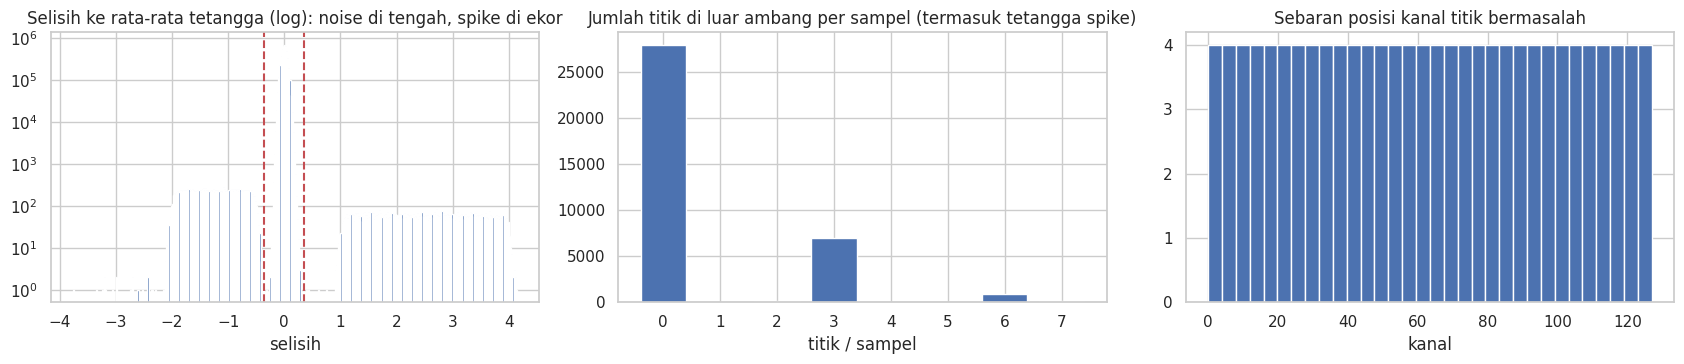

sigma noise (MAD) selisih = 0.0509 | ambang = 7.0 x MAD = 0.356 | sampel dengan >=1 titik di luar ambang = 22.5%
Histogram |selisih| per bin 0.05 (0..1): [3054764, 1233887, 205000, 14549, 587, 20, 1, 9, 36, 194, 396, 533, 586, 623, 608, 607, 616, 640, 637, 633]


In [ ]:
# ---- 4.4 Spike: selisih tiap kanal terhadap rata-rata dua tetangganya ----
def neighbor_diff(X):
    d = np.zeros(X.shape, dtype=np.float64)
    d[:, 1:-1] = X[:, 1:-1] - 0.5 * (X[:, :-2] + X[:, 2:]); d[:, 0] = X[:, 0] - X[:, 1]; d[:, -1] = X[:, -1] - X[:, -2]
    return d

D_RAW = neighbor_diff(X_RAW); SIGMA_D = np.median(np.abs(D_RAW[:, 1:-1])) * 1.4826; THR_D = SPIKE_MAD * SIGMA_D
spike_eda = (np.abs(D_RAW) > THR_D)
per_sample = spike_eda.sum(1)
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
ax[0].hist(D_RAW[:, 1:-1].ravel(), bins=400, log=True); ax[0].axvline(THR_D, c="r", ls="--"); ax[0].axvline(-THR_D, c="r", ls="--")
ax[0].set(title="Selisih ke rata-rata tetangga (log): noise di tengah, spike di ekor", xlabel="selisih")
ax[1].bar(range(0, 8), np.bincount(np.minimum(per_sample, 7), minlength=8)); ax[1].set(title="Jumlah titik di luar ambang per sampel (termasuk tetangga spike)", xlabel="titik / sampel")
ax[2].hist(np.where(spike_eda.any(0), 1, 0).nonzero()[0], bins=L // 4); ax[2].set(title="Sebaran posisi kanal titik bermasalah", xlabel="kanal")
plt.tight_layout(); plt.show()
print(f"sigma noise (MAD) selisih = {SIGMA_D:.4f} | ambang = {SPIKE_MAD} x MAD = {THR_D:.3f} | sampel dengan >=1 titik di luar ambang = {spike_eda.any(1).mean() * 100:.1f}%")
a = np.abs(D_RAW[:, 1:-1]).ravel(); gap = np.histogram(a, bins=np.arange(0, 1.01, .05))[0]
print("Histogram |selisih| per bin 0.05 (0..1):", gap.tolist())

**Interpretasi.** Selisih ke tetangga memperlihatkan **dua populasi yang terpisah jelas**: puncak sempit di sekitar nol (noise) dan ekor lebar jauh di luar (spike), dengan **jurang hampir kosong** di antaranya. Ambang `7 × MAD` jatuh di jurang itu,
jadi pemisahan tidak sensitif terhadap pilihan angka persisnya. Sekitar **seperlima sampel** memuat minimal satu spike, berupa **lonjakan satu kanal yang nyaris selalu positif**, tersebar di seluruh kanal.
Selisih ke tetangga dipakai (bukan median-filter) karena **puncak spektrum yang sah juga sempit**; detektor yang terlalu agresif akan memotong puncak sebenarnya. Tetangga langsung sebuah spike ikut melewati ambang
(selisihnya setengah amplitudo spike), jadi deteksi hanya menandai **maksimum lokal** selisih.

NaN = 0, Inf = 0 -> tidak ada bacaan hilang pada spektrum (float16 mampu menyimpan NaN, jadi ini bukan artefak tipe data).


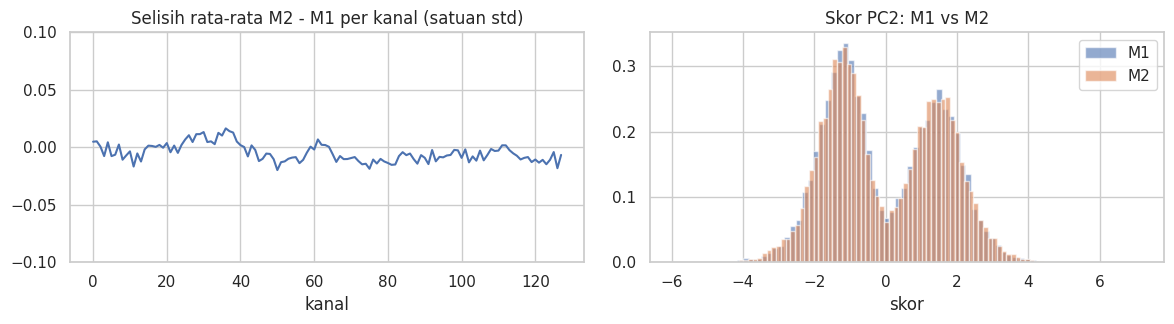

Selisih rata-rata M2-M1 terbesar = 0.0198 std | korelasi 5 PC pertama dengan mikroskop: [np.float64(0.004), np.float64(0.005), np.float64(0.004), np.float64(0.004), np.float64(0.006)]


In [ ]:
# ---- 4.5 Missing values & efek mikroskop pada spektrum ----
print(f"NaN = {n_nan}, Inf = {n_inf} -> tidak ada bacaan hilang pada spektrum (float16 mampu menyimpan NaN, jadi ini bukan artefak tipe data).")
d_mic = (X_RAW[MIC == 1].mean(0) - X_RAW[MIC == 0].mean(0)) / X_RAW.std(0)
Z_pc = S_raw[:, :5]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(d_mic); ax[0].set(title="Selisih rata-rata M2 - M1 per kanal (satuan std)", xlabel="kanal"); ax[0].set_ylim(-0.1, 0.1)
for v, nm in [(0, "M1"), (1, "M2")]: ax[1].hist(S_raw[MIC == v, 1], bins=80, alpha=.6, label=nm, density=True)
ax[1].set(title="Skor PC2: M1 vs M2", xlabel="skor"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Selisih rata-rata M2-M1 terbesar = {np.abs(d_mic).max():.4f} std | korelasi 5 PC pertama dengan mikroskop: {[round(abs(np.corrcoef(Z_pc[:, i], MIC)[0, 1]), 3) for i in range(5)]}")

**Interpretasi.** **Tidak ada nilai hilang** pada spektrum, dan **mikroskop tidak memengaruhi spektrum** (selisih rata-rata M1 vs M2 nyaris nol, korelasi PC dengan mikroskop ≈ 0). Artinya perbedaan mikroskop adalah distorsi khusus **gambar**,
dan modality spektrum bisa dipakai sebagai jangkar yang bebas *domain shift* ketika digabung dengan gambar. Distorsi spektrum yang nyata adalah **baseline, spike, noise, dan geseran puncak** (geseran dikuantifikasi di 5.4).

# SECTION 5 — Preprocessing

## Bagian A — Image
Urutan: **(1)** denoise Gaussian ringan (`SIGMA_IMG`, 0 = tanpa denoise) → **(2)** z-score per gambar (membuang offset kecerahan dan kontras antar-mikroskop) → **(3)** tensor untuk representation learning.
Semua langkah per gambar, tanpa label dan tanpa statistik global, sehingga tidak ada kebocoran.


In [ ]:
if HAS_IMAGES:
    SIGMA_IMG, CLIP_IMG = 0.7, 5.0       # sigma denoise Gaussian (piksel; 0 = tanpa denoise), batas clip hasil z-score

    def preprocess_images(G_u8, sigma=SIGMA_IMG, clip=CLIP_IMG, chunk=6000):
        out = np.empty(G_u8.shape, np.float32)
        for s in range(0, len(G_u8), chunk):
            g = G_u8[s:s + chunk].astype(np.float32)
            if sigma > 0: g = gaussian_filter(g, sigma=(0, sigma, sigma))
            g = (g - g.mean((1, 2), keepdims=True)) / (g.std((1, 2), keepdims=True) + 1e-6)
            out[s:s + chunk] = np.clip(g, -clip, clip)
        return out

    X_IMG = preprocess_images(GAMBAR)
    print(f"Hasil: {X_IMG.shape} {X_IMG.dtype} | rata-rata baris = {X_IMG.mean((1, 2)).mean():+.4f}, std baris = {X_IMG.std((1, 2)).mean():.4f} | NaN = {int(np.isnan(X_IMG).sum())}")

    # ---- 5A.1 Pilihan langkah, diukur TANPA label pada deskriptor invarian rotasi (log profil daya radial) ----
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    from sklearn.pipeline import make_pipeline

    def mic_auc(E, n=8000):
        # Seberapa mudah mikroskop ditebak dari representasi (AUC cross-validation; 0.5 = tidak ada domain shift). Mikroskop hanya metadata, bukan label jenis.
        sub = np.random.default_rng(SEED).choice(len(E), min(n, len(E)), replace=False)
        p = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=300)), E[sub], MIC[sub], cv=5, method="predict_proba")[:, 1]
        return float(roc_auc_score(MIC[sub], p))

    def quick_silhouette(E, ks=range(2, 9)):
        Z = PCA(16, random_state=SEED).fit_transform(E - E.mean(0))
        return max((silhouette_score(Z, KMeans(k, n_init=3, random_state=SEED).fit_predict(Z)), k) for k in ks)

    sub_pp = np.random.default_rng(SEED).choice(N, min(8000, N), replace=False)
    img_variants = {"mentah (tanpa normalisasi)": GAMBAR[sub_pp].astype(np.float32),
                    "z-score saja": preprocess_images(GAMBAR[sub_pp], sigma=0),
                    "z-score + denoise 0.7": preprocess_images(GAMBAR[sub_pp], sigma=0.7),
                    "z-score + denoise 1.2": preprocess_images(GAMBAR[sub_pp], sigma=1.2)}
    rows = []
    for nm, V in img_variants.items():
        D = np.log10(radial_profile(V)[0] + 1e-6); sil, k_ = quick_silhouette(D)
        p = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=300)), D, MIC[sub_pp], cv=5, method="predict_proba")[:, 1]
        rows.append({"langkah": nm, "AUC mikroskop": roc_auc_score(MIC[sub_pp], p), "silhouette terbaik": sil, "pada k": k_})
    IMG_PP_TABLE = pd.DataFrame(rows); print("\n" + IMG_PP_TABLE.round(3).to_string(index=False))
    print(f"Pipeline final memakai SIGMA_IMG = {SIGMA_IMG}. AUC mikroskop turun = domain shift berkurang; silhouette tidak boleh turun jauh = informasi tekstur terjaga.")
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; bagian ini dilewati.")

In [ ]:
if HAS_IMAGES:
    # ---- 5A.2 Visualisasi tiap langkah + tensor ----
    rg = np.random.default_rng(SEED); show = rg.choice(np.where(MIC == 0)[0], 3, replace=False).tolist() + rg.choice(np.where(MIC == 1)[0], 3, replace=False).tolist()
    Z_only = preprocess_images(GAMBAR[show], sigma=0)
    fig, ax = plt.subplots(3, 6, figsize=(14, 7.2))
    for c, i in enumerate(show):
        for r, (im, nm) in enumerate([(GAMBAR[i], "mentah"), (Z_only[c], "z-score"), (X_IMG[i], "final")]):
            ax[r, c].imshow(im, cmap="gray"); ax[r, c].axis("off"); ax[r, c].set_title(f"{'M2' if MIC[i] else 'M1'} #{i} | {nm}", fontsize=8)
    plt.tight_layout(); plt.show()
    print("Setelah normalisasi, kecerahan dan kontras M1 vs M2 sama (rata-rata 0, std 1):",
          {nm: (round(float(X_IMG[MIC == v].mean()), 3), round(float(X_IMG[MIC == v].std((1, 2)).mean()), 3)) for v, nm in [(0, "M1"), (1, "M2")]})

    IMG_T = torch.from_numpy(X_IMG[:, None]).to(DEVICE)             # (N, 1, 64, 64) float32 di GPU (+-590 MB)
    print("Tensor gambar:", tuple(IMG_T.shape), IMG_T.dtype, IMG_T.device, "| urutan baris = urutan meta (IDS[i] <-> IMG_T[i])")
    assert IMG_T.shape == (N, 1, 64, 64) and len(IDS) == N
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; bagian ini dilewati.")

**Interpretasi.** Z-score per gambar menyamakan kecerahan dan kontras M1 dan M2. Derau yang tersisa diukur lewat AUC mikroskop pada tabel 5A.1 dan ditangani augmentasi derau di Bagian C.

## Bagian B — Spectrum
Urutan: **(1)** isi nilai hilang (tidak ada pada data ini, tetapi disiapkan) → **(2)** buang spike → **(3)** koreksi baseline → **(4)** normalisasi per sampel → **(5)** tensor untuk representation learning.

**Tanpa kebocoran:** semua langkah bekerja **per sampel** (tanpa label dan tanpa statistik global yang di-*fit*), sehingga tidak ada informasi dari sampel lain yang bocor ke sampel ini.
Clustering di notebook ini bersifat *transduktif* pada seluruh 36.000 sampel (semua sampel harus mendapat cluster), dan tidak ada label yang dipakai.

In [ ]:
def fill_missing(X):
    # NaN/Inf -> interpolasi linear antar-kanal dalam satu sampel (tidak ada NaN di data ini; jaga-jaga)
    X = X.astype(np.float64).copy(); bad = ~np.isfinite(X); idx = np.arange(X.shape[1])
    for i in np.where(bad.any(1))[0]:
        m = bad[i]; X[i, m] = np.interp(idx[m], idx[~m], X[i, ~m])
    return X, int(bad.sum())

def despike(X, thr_mad=SPIKE_MAD, n_pass=2):
    # Spike = maksimum lokal dari |selisih ke rata-rata tetangga| di atas thr_mad x MAD. Diganti rata-rata kedua tetangganya.
    X = X.copy(); Lc = X.shape[1]; total = np.zeros(X.shape, dtype=bool)
    for _ in range(n_pass):
        d = neighbor_diff(X); thr = thr_mad * np.median(np.abs(d[:, 1:-1])) * 1.4826
        ad = np.abs(d); ap = np.pad(ad, ((0, 0), (1, 1)))
        sp = (ad > thr) & (ad >= ap[:, :-2]) & (ad >= ap[:, 2:])
        ii, jj = np.where(sp)
        if len(ii) == 0: break
        jl, jr = np.where(jj > 0, jj - 1, jj + 1), np.where(jj < Lc - 1, jj + 1, jj - 1)
        X[ii, jj] = 0.5 * (X[ii, jl] + X[ii, jr]); total |= sp
    return X, total

def remove_baseline(X, deg=BASE_DEG, iters=BASE_ITERS):
    # Baseline polinomial dengan pemotongan iteratif (gaya ModPoly): nilai di atas kurva dipotong ke kurva,
    # sehingga puncak tidak menarik baseline ke atas. Operasi linear -> vektor untuk semua sampel sekaligus.
    Lc = X.shape[1]; V = np.vander(np.linspace(-1, 1, Lc), deg + 1); H = V @ np.linalg.pinv(V)
    y = X.T.copy()
    for _ in range(iters):
        y = np.minimum(X.T, H @ y)
    return X - y.T, y.T

def zscore_rows(X):
    return (X - X.mean(1, keepdims=True)) / (X.std(1, keepdims=True) + 1e-8)

def preprocess_spectra(X):
    X_fill, n_fill = fill_missing(X)
    X_desp, spk = despike(X_fill)
    X_base, base = remove_baseline(X_desp)
    return {"fill": X_fill, "despike": X_desp, "spike_mask": spk, "baseline": base, "corrected": X_base,
            "final": zscore_rows(X_base).astype(np.float32), "n_filled": n_fill}

PP = preprocess_spectra(X_RAW)
X_PP = PP["final"]
print(f"Nilai hilang diisi: {PP['n_filled']} | spike dibuang: {int(PP['spike_mask'].sum())} pada {PP['spike_mask'].any(1).mean() * 100:.1f}% sampel "
      f"(maks {int(PP['spike_mask'].sum(1).max())} per sampel)")
d_after = neighbor_diff(PP["despike"]); print(f"Titik di luar ambang setelah despike: {int((np.abs(d_after) > THR_D).sum())} dari {d_after.size} (sebelum: {int(spike_eda.sum())})")
print(f"Setelah normalisasi: rata-rata baris = {X_PP.mean(1).mean():+.4f}, std baris = {X_PP.std(1).mean():.4f} | NaN = {int(np.isnan(X_PP).sum())}")
np.save(OUTPUT_DIR / "spektrum_bersih.npy", X_PP)

Nilai hilang diisi: 0 | spike dibuang: 9337 pada 22.5% sampel (maks 6 per sampel)
Titik di luar ambang setelah despike: 143 dari 4608000 (sebelum: 27477)
Setelah normalisasi: rata-rata baris = -0.0000, std baris = 1.0000 | NaN = 0


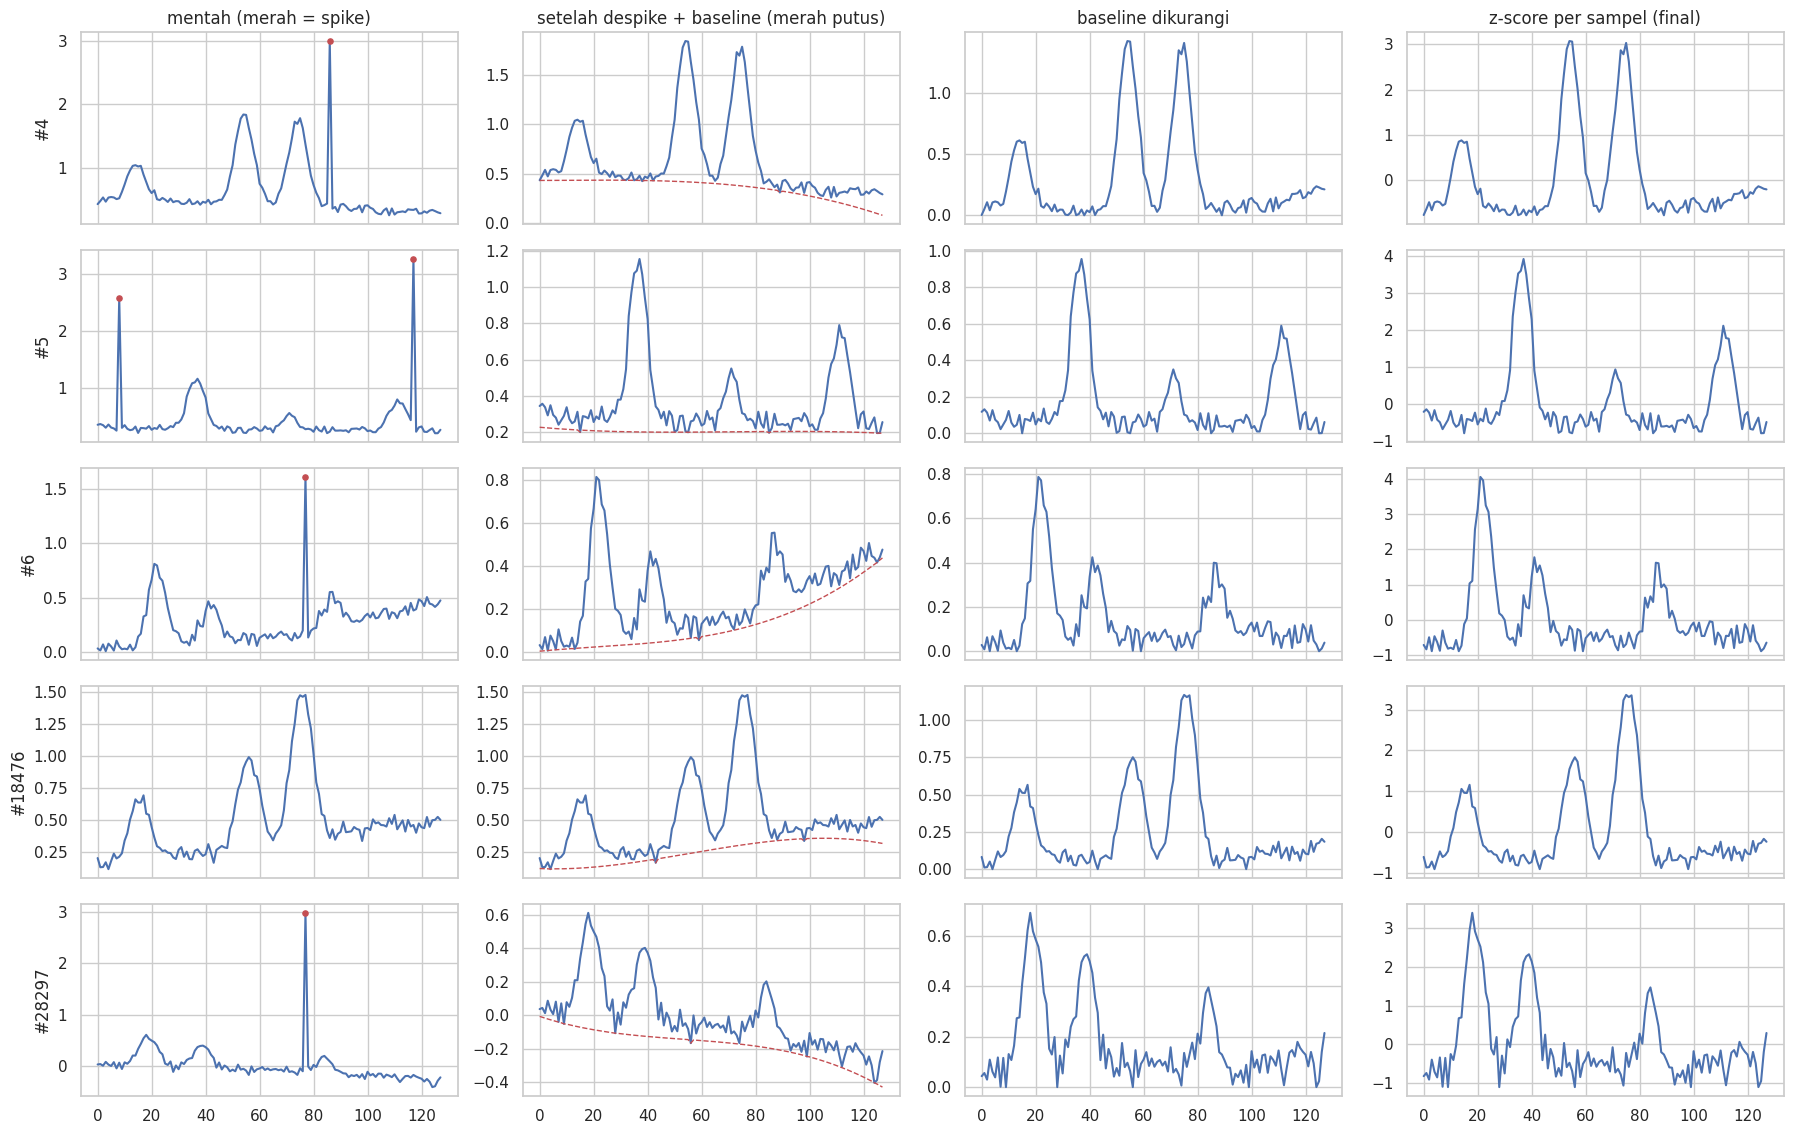

In [ ]:
# ---- 5.1 Visualisasi tiap langkah pada beberapa sampel ----
sel = np.where(PP["spike_mask"].any(1))[0][:3].tolist() + rng.choice(N, 2, replace=False).tolist()
fig, ax = plt.subplots(len(sel), 4, figsize=(18, 2.3 * len(sel)), sharex=True)
for r, i in enumerate(sel):
    ax[r, 0].plot(X_RAW[i]); ax[r, 1].plot(PP["despike"][i]); ax[r, 1].plot(PP["baseline"][i], "r--", lw=1)
    ax[r, 2].plot(PP["corrected"][i]); ax[r, 3].plot(X_PP[i])
    sp = np.where(PP["spike_mask"][i])[0]; ax[r, 0].scatter(sp, X_RAW[i, sp], c="r", s=14, zorder=3)
    ax[r, 0].set_ylabel(f"#{i}")
for c, tt in enumerate(["mentah (merah = spike)", "setelah despike + baseline (merah putus)", "baseline dikurangi", "z-score per sampel (final)"]): ax[0, c].set_title(tt)
plt.tight_layout(); plt.show()

In [ ]:
# ---- 5.2 Kontribusi tiap langkah, diukur TANPA label: kualitas pemisahan cluster (silhouette terbaik untuk k=2..8) ----
def prep_for_cluster(E, n=16):
    E = np.asarray(E, dtype=np.float64); return PCA(min(n, E.shape[1]), random_state=SEED).fit_transform(E - E.mean(0))

def cluster_quality(E, ks=range(2, 9), n_sample=8000):
    Z = prep_for_cluster(E); sub = np.random.default_rng(SEED).choice(len(Z), min(n_sample, len(Z)), replace=False); rows = []
    for k in ks:
        lab = KMeans(k, n_init=3, random_state=SEED).fit_predict(Z[sub])
        rows.append((k, silhouette_score(Z[sub], lab), davies_bouldin_score(Z[sub], lab), calinski_harabasz_score(Z[sub], lab)))
    return pd.DataFrame(rows, columns=["k", "silhouette", "DB", "CH"])

variants = {"z-score saja (tanpa pembersihan)": zscore_rows(PP["fill"]),
            "+ despike": zscore_rows(PP["despike"]),
            "+ baseline (tanpa despike)": zscore_rows(remove_baseline(PP["fill"])[0]),
            "+ despike + baseline (final)": X_PP}
rows = []
for nm, F_ in variants.items():
    q = cluster_quality(F_); b = q.loc[q["silhouette"].idxmax()]; rows.append({"langkah": nm, "silhouette terbaik": b["silhouette"], "pada k": int(b["k"]), "DB di k itu": b["DB"]})
tab_pp = pd.DataFrame(rows); print(tab_pp.round(3).to_string(index=False))
N_SPEC_GROUPS = int(tab_pp.iloc[-1]["pada k"]); print(f"\nJumlah kelompok spektral yang terbaik setelah pembersihan (k dengan silhouette tertinggi): {N_SPEC_GROUPS}")

                         langkah  silhouette terbaik  pada k  DB di k itu
z-score saja (tanpa pembersihan)               0.339       4        1.229
                       + despike               0.359       4        1.184
      + baseline (tanpa despike)               0.448       4        0.929
    + despike + baseline (final)               0.483       4        0.866

Jumlah kelompok spektral yang terbaik setelah pembersihan (k dengan silhouette tertinggi): 4


**Interpretasi.** Tiap langkah pembersihan menaikkan keterpisahan cluster yang terukur **tanpa label apa pun**, dan kombinasi despike + baseline memberi hasil terbaik. Hasil akhir juga menunjukkan bahwa spektrum
bersih membentuk **sejumlah kecil kelompok spektral yang jelas** (kolom "pada k"). Perlu dicatat bahwa k dengan silhouette tertinggi pada **spektrum saja** belum tentu jumlah jenis material sebenarnya:
dua jenis material dapat berbagi pola spektrum yang sama dan hanya dibedakan oleh gambar (dianalisis di Section 8–11).

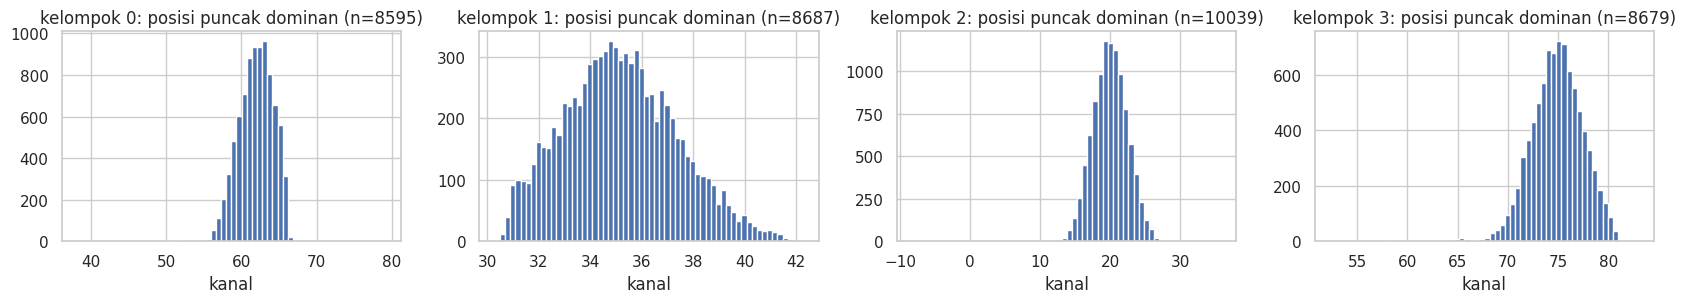

Std geseran puncak per kelompok (kanal): [2.39, 2.19, 2.46, 2.61] | persentil 1/99 geseran: [-5.5, 5.2]


In [ ]:
# ---- 5.3 Posisi puncak setelah pembersihan: apakah geseran puncak kontinu (distorsi) atau terpisah jadi beberapa mode? ----
def estimate_peak_shift(X, n_groups):
    Z = PCA(12, random_state=SEED).fit_transform(X); g = KMeans(n_groups, n_init=5, random_state=SEED).fit_predict(Z)
    S = gaussian_filter1d(X, 2.0, axis=1, mode="nearest"); shift = np.zeros(len(X)); pos_all = np.zeros(len(X)); Lc = X.shape[1]
    for c in range(n_groups):
        m = np.where(g == c)[0]; Sg = S[m]; modal = np.bincount(Sg.argmax(1)).argmax()
        lo, hi = max(modal - 12, 1), min(modal + 12, Lc - 2); a = Sg[:, lo:hi].argmax(1) + lo; r = np.arange(len(a))
        y0, y1, y2 = Sg[r, a - 1], Sg[r, a], Sg[r, a + 1]; pos = a + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2 + 1e-9)
        shift[m] = pos - np.median(pos); pos_all[m] = pos
    return shift, g, pos_all

SHIFT, G_SPEC, POS_PEAK = estimate_peak_shift(X_PP, N_SPEC_GROUPS)
fig, ax = plt.subplots(1, N_SPEC_GROUPS, figsize=(4.2 * N_SPEC_GROUPS, 3.2))
for c in range(N_SPEC_GROUPS):
    ax[c].hist(POS_PEAK[G_SPEC == c], bins=60, color="#4c72b0"); ax[c].set_title(f"kelompok {c}: posisi puncak dominan (n={int((G_SPEC == c).sum())})"); ax[c].set_xlabel("kanal")
plt.tight_layout(); plt.show()
print("Std geseran puncak per kelompok (kanal):", [round(float(SHIFT[G_SPEC == c].std()), 2) for c in range(N_SPEC_GROUPS)],
      "| persentil 1/99 geseran:", np.percentile(SHIFT, [1, 99]).round(1).tolist())

**Interpretasi.** Di dalam tiap kelompok spektral, posisi puncak dominan menyebar **kontinu dan satu-puncak (unimodal)** dengan simpangan baku sekitar 2 kanal dan rentang kira-kira ±5 kanal. Ini adalah **distorsi geseran** (sesuai ketentuan UTS), bukan
penanda kelas yang terpisah. Dua implikasi: **(1)** KMeans pada spektrum mentah akan cenderung **memecah satu jenis material menjadi dua** hanya karena geseran (itulah sebabnya jumlah cluster yang dipilih harus diuji dengan banyak kriteria, Section 11);
**(2)** representasi spektrum harus **tahan terhadap geseran ±5 kanal** tetapi tetap membedakan kelompok yang puncaknya berjarak puluhan kanal. Inilah dasar augmentasi pada Section 7.
`SHIFT` (geseran per sampel) hanya dipakai sebagai **diagnostik** untuk mengukur seberapa jauh sebuah embedding masih "menyimpan" geseran; ia tidak dipakai untuk melatih apa pun.

In [ ]:
# ---- 5.4 Persiapan tensor ----
X_T = torch.from_numpy(X_PP[:, None, :]).to(DEVICE)       # (N, 1, 128) float32, seluruhnya di GPU (+-18 MB)
print("Tensor spektrum:", tuple(X_T.shape), X_T.dtype, X_T.device, "| urutan baris = urutan meta (IDS[i] <-> X_T[i])")
assert X_T.shape == (N, 1, L) and len(IDS) == N

Tensor spektrum: (36000, 1, 128) torch.float32 cuda:0 | urutan baris = urutan meta (IDS[i] <-> X_T[i])


## Bagian C — Image Representation Learning dan Image Embedding (Anggota 1)
**Metode:** *contrastive encoder* CNN (SimCLR, loss NT-Xent) tanpa label. Dua tampilan acak dari gambar yang sama menjadi pasangan positif. Augmentasi meniru distorsi dari EDA (rotasi, skala, translasi, derau berbeda antar-mikroskop, gradien pencahayaan), jadi embedding hanya menyimpan jenis tekstur. Pembanding: PCA pada piksel.
Embedding akhir disimpan ke `embedding_gambar.npz` (format Section 6) dan dibaca kembali oleh Section 6.

In [ ]:
if HAS_IMAGES:
    import math
    IMG_EMB_DIM, IMG_CL_EPOCHS, IMG_BATCH, IMG_LR, IMG_TAU = 64, 40, 512, 1e-3, 0.2

    class ImgEncoder(nn.Module):
        # 4 blok (conv3x3 + conv3x3 stride 2): 64 -> 32 -> 16 -> 8 -> 4; global average pooling -> linear -> embedding
        def __init__(self, emb_dim=IMG_EMB_DIM, ch=(32, 64, 128, 256)):
            super().__init__(); layers, cin = [], 1
            for c in ch:
                layers += [nn.Conv2d(cin, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.GELU(),
                           nn.Conv2d(c, c, 3, padding=1, stride=2, bias=False), nn.BatchNorm2d(c), nn.GELU()]; cin = c
            self.conv = nn.Sequential(*layers); self.pool = nn.AdaptiveAvgPool2d(1); self.fc = nn.Linear(ch[-1], emb_dim)
        def forward(self, x): return self.fc(self.pool(self.conv(x)).flatten(1))

    class ImgContrastive(nn.Module):
        def __init__(self, emb_dim=IMG_EMB_DIM):
            super().__init__(); self.enc = ImgEncoder(emb_dim); self.head = nn.Sequential(nn.Linear(emb_dim, 128), nn.ReLU(), nn.Linear(128, 64))
        def forward(self, x): return self.head(self.enc(x))

    def img_affine(x, angle, scale, tx, ty, flip):
        # Rotasi (radian), zoom, translasi, dan cermin; padding refleksi agar tidak ada sudut kosong.
        c, s = torch.cos(angle) / scale, torch.sin(angle) / scale
        A = torch.stack([torch.stack([c * flip, -s, tx], 1), torch.stack([s * flip, c, ty], 1)], 1)       # (B, 2, 3)
        return F.grid_sample(x, F.affine_grid(A, list(x.shape), align_corners=False), mode="bilinear", padding_mode="reflection", align_corners=False)

    _BLUR_K = torch.tensor([[1., 2., 1.], [2., 4., 2.], [1., 2., 1.]]) / 16

    def img_augment(x, scale_rng=(0.8, 1.25), shift=0.15, noise_max=0.35, grad_amp=0.25, blur_p=0.5):
        # x: (B, 1, 64, 64) z-score. Semua operasi di GPU dan acak per gambar; hasil dinormalisasi ulang per gambar.
        B, dev = x.size(0), x.device
        angle = torch.rand(B, device=dev) * 2 * math.pi
        scale = torch.empty(B, device=dev).uniform_(*scale_rng)
        flip = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1
        tx, ty = (torch.rand(2, B, device=dev) * 2 - 1) * shift
        out = img_affine(x, angle, scale, tx, ty, flip)
        blurred = F.conv2d(F.pad(out, (1, 1, 1, 1), mode="reflect"), _BLUR_K.to(dev)[None, None])
        out = torch.where(torch.rand(B, 1, 1, 1, device=dev) < blur_p, blurred, out)                      # blur ringan
        g = torch.linspace(-1, 1, x.size(-1), device=dev)
        out = out + torch.randn(B, 1, 1, 1, device=dev) * grad_amp / 2 * g[None, None, None, :] + torch.randn(B, 1, 1, 1, device=dev) * grad_amp / 2 * g[None, None, :, None]   # gradien pencahayaan
        out = out + torch.randn_like(out) * torch.rand(B, 1, 1, 1, device=dev) * noise_max                # derau dengan level acak (menjembatani M1 dan M2)
        return (out - out.mean((2, 3), keepdim=True)) / (out.std((2, 3), keepdim=True) + 1e-6)

    def img_nt_xent(z1, z2, tau=IMG_TAU):
        n = z1.size(0); z = F.normalize(torch.cat([z1, z2]), dim=1); sim = z @ z.T / tau
        sim = sim.masked_fill(torch.eye(2 * n, dtype=torch.bool, device=z.device), -1e9)
        return F.cross_entropy(sim, torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device))

    def train_img_contrastive(model, epochs=IMG_CL_EPOCHS, bs=IMG_BATCH, lr=IMG_LR):
        model.to(DEVICE).train(); nb = len(IMG_T) // bs
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * nb); hist = {"loss": []}
        for ep in range(epochs):
            perm = torch.randperm(len(IMG_T), device=DEVICE); run = 0.0
            for i in range(nb):
                xb = IMG_T[perm[i * bs:(i + 1) * bs]]
                with torch.no_grad(): v1, v2 = img_augment(xb), img_augment(xb)
                loss = img_nt_xent(model(v1), model(v2))
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); run += loss.item()
            hist["loss"].append(run / nb)
            if ep == 0 or (ep + 1) % 10 == 0: print(f"[img contrastive] epoch {ep + 1:03d}/{epochs} | NT-Xent = {run / nb:.4f}")
        return hist

    def img_fit_or_load(name, model, train_fn):
        # Cache bobot + riwayat loss di OUTPUT_DIR; jika ada dan RETRAIN=False tidak dilatih ulang.
        ckpt, hf = OUTPUT_DIR / f"{name}.pt", OUTPUT_DIR / f"{name}_hist.json"
        if ckpt.exists() and hf.exists() and not RETRAIN:
            model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); model.to(DEVICE); hist = json.load(open(hf)); print(f"[{name}] dimuat dari cache {ckpt}")
        else:
            hist = train_fn(model); torch.save(model.state_dict(), ckpt); json.dump(hist, open(hf, "w")); print(f"[{name}] bobot disimpan: {ckpt}")
        return model, hist

    def img_embed(enc, X, bs=2048, tta=True):
        # tta: rata-rata embedding dari 4 rotasi 90 derajat (tambahan invarian rotasi)
        enc.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(X), bs):
                xb = X[i:i + bs]; views = [torch.rot90(xb, k, (2, 3)) for k in range(4)] if tta else [xb]
                out.append(torch.stack([enc(v) for v in views]).mean(0).float().cpu().numpy())
        return np.concatenate(out)
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; bagian ini dilewati.")

In [ ]:
if HAS_IMAGES:
    # [TORCH-RUN] latih (atau muat dari cache) contrastive encoder gambar, lalu ekstrak embedding
    set_seed(); img_model, HIST_IMG = img_fit_or_load("img_contrastive", ImgContrastive(), train_img_contrastive)
    E_IMG_CL = img_embed(img_model.enc, IMG_T)

    # Pembanding: PCA pada piksel (fit pada subsampel, tanpa label)
    sub_fit = np.random.default_rng(SEED).choice(N, min(10000, N), replace=False); Xf = X_IMG.reshape(N, -1)
    pca_img = PCA(IMG_EMB_DIM, svd_solver="randomized", random_state=SEED).fit(Xf[sub_fit]); E_IMG_PCA = pca_img.transform(Xf).astype(np.float32)
    np.save(OUTPUT_DIR / "emb_gambar_contrastive.npy", E_IMG_CL); np.save(OUTPUT_DIR / "emb_gambar_pca.npy", E_IMG_PCA)
    print("Embedding:", E_IMG_CL.shape, E_IMG_PCA.shape)
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; bagian ini dilewati.")

In [ ]:
if HAS_IMAGES:
    # ---- Loss, contoh augmentasi, dan tetangga terdekat di ruang embedding ----
    fig, ax = plt.subplots(1, 1, figsize=(5.5, 3.2)); ax.plot(HIST_IMG["loss"], c="#c44e52"); ax.set(title="Contrastive gambar: NT-Xent", xlabel="epoch"); plt.tight_layout(); plt.show()

    set_seed(); demo = IMG_T[:4]; views = [img_augment(demo).cpu().numpy()[:, 0] for _ in range(3)]
    fig, ax = plt.subplots(4, 4, figsize=(8, 8))
    for r in range(4):
        ax[r, 0].imshow(X_IMG[r], cmap="gray"); ax[r, 0].set_title("asli" if r == 0 else "", fontsize=8)
        for c in range(3): ax[r, c + 1].imshow(views[c][r], cmap="gray"); ax[r, c + 1].set_title(f"augmentasi {c + 1}" if r == 0 else "", fontsize=8)
    for a in ax.ravel(): a.axis("off")
    plt.tight_layout(); plt.show()

    Ec = E_IMG_CL - E_IMG_CL.mean(0); nn_idx = NearestNeighbors(n_neighbors=7, metric="cosine").fit(Ec)
    qs = np.random.default_rng(SEED).choice(N, 5, replace=False); nbr = nn_idx.kneighbors(Ec[qs], return_distance=False)
    fig, ax = plt.subplots(5, 7, figsize=(12, 8.6))
    for r in range(5):
        for c in range(7):
            i = nbr[r, c]; ax[r, c].imshow(GAMBAR[i], cmap="gray", vmin=0, vmax=255); ax[r, c].axis("off")
            ax[r, c].set_title(("query " if c == 0 else "") + f"{'M2' if MIC[i] else 'M1'} #{i}", fontsize=7, color="r" if c == 0 else "k")
    plt.suptitle("Tetangga terdekat di ruang embedding (kolom pertama = query): tekstur sama pada orientasi/mikroskop berbeda"); plt.tight_layout(); plt.show()
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; bagian ini dilewati.")

In [ ]:
if HAS_IMAGES:
    # ---- Evaluasi representasi gambar TANPA label ----
    def rot_invariance(fn, n=2000, angle_deg=37.0):
        # Kosinus (embedding terpusat) antara gambar dan versi diputar vs. pasangan acak; fn: tensor (B,1,64,64) -> ndarray
        rg = np.random.default_rng(SEED); x = IMG_T[torch.as_tensor(rg.choice(N, n, replace=False), device=IMG_T.device)]; B = len(x)
        one, zero = torch.ones(B, device=x.device), torch.zeros(B, device=x.device)
        xr = img_affine(x, one * math.radians(angle_deg), one, zero, zero, one)
        e0, e1 = fn(x), fn(xr); mu = e0.mean(0); e0, e1 = e0 - mu, e1 - mu
        cs = lambda p, q: (p * q).sum(1) / (np.linalg.norm(p, axis=1) * np.linalg.norm(q, axis=1) + 1e-9)
        return float(cs(e0, e1).mean()), float(cs(e0, e1[rg.permutation(B)]).mean())

    fn_cl = lambda x: img_embed(img_model.enc, x)
    fn_pca = lambda x: pca_img.transform(x.reshape(len(x), -1).cpu().numpy())
    rows = []
    for nm, E, fn in [("PCA piksel (64-d)", E_IMG_PCA, fn_pca), ("Contrastive CNN (64-d)", E_IMG_CL, fn_cl)]:
        q = cluster_quality(E); b = q.loc[q["silhouette"].idxmax()]; inv, base = rot_invariance(fn)
        rows.append({"representasi": nm, "silhouette terbaik": b["silhouette"], "pada k": int(b["k"]), "DB di k itu": b["DB"], "AUC mikroskop": mic_auc(E),
                     "kosinus asli vs diputar": inv, "kosinus pasangan acak": base})
    IMG_REPR_TABLE = pd.DataFrame(rows); print(IMG_REPR_TABLE.round(3).to_string(index=False))
    print("\nAUC mikroskop: 0.5 = embedding tidak memuat identitas mikroskop (lebih rendah lebih baik). Kosinus asli vs diputar harus jauh di atas pasangan acak (invarian rotasi).")
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; bagian ini dilewati.")

In [ ]:
if HAS_IMAGES:
    # ---- Simpan image embedding (format Section 6) ----
    E_IMG_FINAL = E_IMG_CL.astype(np.float32)
    assert E_IMG_FINAL.shape == (N, IMG_EMB_DIM) and np.isfinite(E_IMG_FINAL).all()
    np.savez(OUTPUT_DIR / IMG_EMB_FILE, **{IMG_ID_KEY: IDS.astype(str), IMG_EMB_KEY: E_IMG_FINAL})
    chk_emb = np.load(OUTPUT_DIR / IMG_EMB_FILE, allow_pickle=False)
    assert (chk_emb[IMG_ID_KEY] == IDS).all() and chk_emb[IMG_EMB_KEY].shape == (N, IMG_EMB_DIM)
    print(f"Tersimpan: {(OUTPUT_DIR / IMG_EMB_FILE).resolve()} | id_sampel {chk_emb[IMG_ID_KEY].shape} | embedding {chk_emb[IMG_EMB_KEY].shape} {chk_emb[IMG_EMB_KEY].dtype}")
    print("Berkas ini dibaca Section 6 dan ikut terunduh di task3_outputs.zip (Section 15); kirim ke Anggota 2 bila notebook dijalankan terpisah.")
else:
    print("Array 'gambar' tidak ada pada berkas yang dipakai; bagian ini dilewati.")

**Interpretasi.** Embedding contrastive dipilih sebagai image embedding karena dilatih invarian terhadap distorsi (rotasi, skala, derau, pencahayaan). Cek tabel di atas: AUC mikroskop mendekati 0,5 dan kosinus asli vs diputar jauh di atas pasangan acak menandakan embedding mengikuti tekstur, bukan mikroskop atau orientasi.
**Keterbatasan.** Satu run training; tanpa label, mutu pemisahan jenis material hanya diukur secara internal. Rotasi dan skala diasumsikan distorsi (EDA 4A.3 dan 4A.4); bila ternyata menandai jenis material, persempit rentang augmentasi.

# SECTION 6 — Image Representation Integration

Bagian ini **memuat image embedding dari Anggota 1**. Format file **belum disepakati** pada saat notebook ini ditulis, jadi yang dipakai di bawah adalah **usulan** yang bisa diubah lewat `IMG_EMB_FILE`, `IMG_ID_KEY`, `IMG_EMB_KEY` (Section 3):

| Isi `embedding_gambar.npz` | Keterangan |
|---|---|
| `id_sampel` | array string (N,), ID tiap baris embedding |
| `embedding` | array float (N, D), embedding gambar |

Loader mengurutkan ulang baris embedding mengikuti `clustering_meta.csv` berdasarkan `id_sampel`, sehingga urutan baris pada file Anggota 1 tidak harus sama. Contoh cara Anggota 1 menyimpan (di notebook-nya):
```python
meta = pd.read_csv("clustering_meta.csv")              # baris i meta <-> gambar[i]
np.savez("embedding_gambar.npz", id_sampel=meta["id_sampel"].to_numpy().astype(str), embedding=emb.astype(np.float32))
```
Di Colab, jika file belum ada, cell di bawah membuka **dialog unggah dari PC** (pilih `embedding_gambar.npz`; tutup/batalkan dialog bila belum ada).
Jika file **belum tersedia**, proses **fusion dihentikan** (Section 8) dan notebook tetap berjalan dengan **spektrum saja** sebagai mode sementara. Mode itu **tidak** menulis `cluster.csv` final.

In [ ]:
def find_img_emb():
    for d in [DATA_DIR, OUTPUT_DIR, Path("."), Path("/content/drive/MyDrive/dataset"), Path("/content/drive/MyDrive")]:
        if (Path(d) / IMG_EMB_FILE).exists():
            return Path(d) / IMG_EMB_FILE
    return None

def load_image_embeddings(path):
    z = np.load(path, allow_pickle=False)
    assert IMG_ID_KEY in z.files and IMG_EMB_KEY in z.files, f"kunci '{IMG_ID_KEY}'/'{IMG_EMB_KEY}' tidak ada; kunci di file: {z.files}"
    ids, E = z[IMG_ID_KEY].astype(str), z[IMG_EMB_KEY]
    assert E.ndim == 2 and len(ids) == len(E), f"bentuk embedding {E.shape} tidak cocok dengan {len(ids)} ID"
    assert len(E) == N, f"jumlah embedding {len(E)} != jumlah sampel {N}"
    assert len(set(ids)) == N, "id_sampel pada file embedding tidak unik"
    assert set(ids) == set(IDS), f"ID tidak cocok dengan meta: {len(set(ids) - set(IDS))} ID asing, {len(set(IDS) - set(ids))} ID hilang"
    same_order = bool((ids == IDS).all())
    E = E[pd.Series(np.arange(N), index=ids).loc[IDS].to_numpy()]            # urutkan ulang mengikuti meta
    assert np.isfinite(E).all(), "embedding gambar mengandung NaN/Inf"
    return E.astype(np.float32), same_order

IMG_EMB_PATH = find_img_emb()
if IMG_EMB_PATH is None and IN_COLAB and ASK_UPLOAD_IMG_EMB:
    print(f"Pilih {IMG_EMB_FILE} dari Anggota 1 (batalkan dialog jika belum ada):")
    upload_files(DATA_DIR); IMG_EMB_PATH = find_img_emb()
if IMG_EMB_PATH is None:
    HAS_IMG, E_IMG = False, None
    print("=" * 100); print(f"EMBEDDING GAMBAR BELUM TERSEDIA ({IMG_EMB_FILE} tidak ditemukan di {DATA_DIR}, {OUTPUT_DIR}, atau folder kerja).")
    print("Fusion (Section 8) DIHENTIKAN. Minta file ke Anggota 1, taruh di folder dataset, lalu Run all ulang.")
    print("Sementara itu, notebook berjalan dalam MODE 'spektrum_saja' (hasilnya BUKAN hasil akhir).")
    print("=" * 100)
else:
    E_IMG, same_order = load_image_embeddings(IMG_EMB_PATH); HAS_IMG = True
    print(f"Memuat {IMG_EMB_PATH}")
    print(f"Embedding gambar: {E_IMG.shape} {E_IMG.dtype} | jumlah sampel = {len(E_IMG)} (= N) | semua ID cocok dengan meta | urutan asli sama dengan meta: {same_order}")
    print(f"Norma L2 rata-rata = {np.linalg.norm(E_IMG, axis=1).mean():.3f} | rentang nilai [{E_IMG.min():.3f}, {E_IMG.max():.3f}] | dimensi D = {E_IMG.shape[1]}")
MODE = "multimodal" if HAS_IMG else "spektrum_saja"
print("MODE =", MODE)

Pilih embedding_gambar.npz dari Anggota 1 (batalkan dialog jika belum ada):


Tersimpan di /content/dataset : []
EMBEDDING GAMBAR BELUM TERSEDIA (embedding_gambar.npz tidak ditemukan di dataset, outputs, atau folder kerja).
Fusion (Section 8) DIHENTIKAN. Minta file ke Anggota 1, taruh di folder dataset, lalu Run all ulang.
Sementara itu, notebook berjalan dalam MODE 'spektrum_saja' (hasilnya BUKAN hasil akhir).
MODE = spektrum_saja


# SECTION 7 — Spectrum Representation Learning

Tiga representasi spektrum dibandingkan (semua tanpa label):

| Metode | Ide | Catatan |
|---|---|---|
| **PCA** (baseline non-DL) | proyeksi linear | pembanding |
| **Autoencoder konvolusi (AE)** | latent 32-d yang harus merekonstruksi spektrum | menyimpan *segala sesuatu* termasuk geseran, noise |
| **Contrastive encoder (SimCLR-style, NT-Xent)** | dua versi terdistorsi dari sampel yang sama harus punya embedding berdekatan; sampel lain ditolak | **invarian terhadap distorsi yang kita augmentasi** |

**Alasan memilih contrastive sebagai kandidat utama:** EDA (Section 4–5) menunjukkan distorsi spektrum adalah **geseran, baseline, spike, noise**. Representasi yang baik harus **mengabaikan** hal-hal itu dan hanya menyimpan pola puncak (jenis material). Augmentasi contrastive memaksakan hal tersebut secara eksplisit.

**Augmentasi (meniru distorsi nyata):**
* **Geser** kontinu ±`SHIFT_MAX` (6) kanal, interpolasi linear: meniru geseran puncak ±5 kanal (5.3). Dipilih lebih kecil dari jarak antar-kelompok sehingga kelompok berbeda tidak ikut "dihapus".
* **Skala amplitudo** ×[0,8; 1,25]: meniru perbedaan kuat sinyal.
* **Baseline halus acak** (polinomial derajat 2): meniru sisa baseline.
* **Noise Gaussian** (std 0,15 pada satuan z-score).
* **Spike acak** satu kanal (peluang 0,2): meniru spike yang lolos deteksi.

Embedding dihitung dengan **flatten** (bukan *global average pooling*) pada akhir encoder agar **posisi kasar puncak** (penanda jenis material) tetap terbawa; invarian terhadap geseran kecil dipelajari lewat augmentasi.

In [ ]:
class SpecEncoder(nn.Module):
    # 3 blok Conv1d (stride 2): 128 -> 64 -> 32 -> 16 kanal; flatten + linear -> embedding EMB_DIM
    def __init__(self, emb_dim=EMB_DIM, ch=(32, 64, 128)):
        super().__init__()
        layers, cin = [], 1
        for c in ch:
            layers += [nn.Conv1d(cin, c, 5, padding=2), nn.BatchNorm1d(c), nn.GELU(),
                       nn.Conv1d(c, c, 5, padding=2, stride=2), nn.BatchNorm1d(c), nn.GELU()]
            cin = c
        self.conv = nn.Sequential(*layers); self.flat = nn.Flatten(); self.fc = nn.Linear(ch[-1] * (L // 8), emb_dim)
    def forward(self, x):                      # x: (B, 1, L)
        return self.fc(self.flat(self.conv(x)))

class ContrastiveModel(nn.Module):
    def __init__(self, emb_dim=EMB_DIM):
        super().__init__()
        self.enc = SpecEncoder(emb_dim); self.head = nn.Sequential(nn.Linear(emb_dim, 128), nn.ReLU(), nn.Linear(128, 64))
    def forward(self, x):
        return self.head(self.enc(x))

class SpecAE(nn.Module):
    def __init__(self, emb_dim=EMB_DIM, ch=(32, 64, 128)):
        super().__init__()
        self.enc = SpecEncoder(emb_dim, ch); self.ch = ch; self.fc = nn.Linear(emb_dim, ch[-1] * (L // 8))
        dec, cin = [], ch[-1]
        for c in (64, 32, 16):
            dec += [nn.ConvTranspose1d(cin, c, 4, stride=2, padding=1), nn.BatchNorm1d(c), nn.GELU()]; cin = c
        dec += [nn.Conv1d(cin, 1, 5, padding=2)]; self.dec = nn.Sequential(*dec)
    def forward(self, x):
        z = self.enc(x); h = self.fc(z).view(-1, self.ch[-1], L // 8); return self.dec(h), z

def augment(x, shift_max=SHIFT_MAX, noise_std=0.15, scale_rng=(0.8, 1.25), base_amp=0.15, spike_p=0.2):
    # x: (B, 1, L) z-score. Semua operasi di GPU dan acak per sampel.
    B, _, Lc = x.shape; dev = x.device; xs = x[:, 0]
    s = (torch.rand(B, 1, device=dev) * 2 - 1) * shift_max                              # geser kontinu (kanal)
    pos = (torch.arange(Lc, device=dev)[None, :].float() - s).clamp(0, Lc - 1)
    i0 = pos.floor().long(); i1 = (i0 + 1).clamp(max=Lc - 1); w = pos - i0.float()
    out = (1 - w) * xs.gather(1, i0) + w * xs.gather(1, i1)                              # interpolasi linear
    out = out * torch.empty(B, 1, device=dev).uniform_(*scale_rng)                       # skala
    t = torch.linspace(-1, 1, Lc, device=dev)[None, :]; c = torch.randn(B, 3, device=dev) * base_amp
    out = out + c[:, 0:1] + c[:, 1:2] * t + c[:, 2:3] * (t ** 2 - 0.5)                  # baseline halus
    out = out + torch.randn_like(out) * noise_std                                        # noise
    has = (torch.rand(B, 1, device=dev) < spike_p).float(); at = torch.randint(0, Lc, (B, 1), device=dev)
    amp = (torch.rand(B, 1, device=dev) * 3 + 2) * (torch.randint(0, 2, (B, 1), device=dev).float() * 2 - 1)
    out = out.scatter_add(1, at, amp * has)                                              # spike
    return out[:, None, :]

def nt_xent(z1, z2, tau=TAU):
    n = z1.size(0); z = F.normalize(torch.cat([z1, z2]), dim=1); sim = z @ z.T / tau
    sim = sim.masked_fill(torch.eye(2 * n, dtype=torch.bool, device=z.device), -1e9)
    target = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    return F.cross_entropy(sim, target)

def train_contrastive(model, epochs=CL_EPOCHS, bs=BATCH, lr=LR):
    model.to(DEVICE).train(); nb = len(X_T) // bs
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * nb); hist = {"loss": []}
    for ep in range(epochs):
        perm = torch.randperm(len(X_T), device=DEVICE); run = 0.0
        for i in range(nb):
            xb = X_T[perm[i * bs:(i + 1) * bs]]
            loss = nt_xent(model(augment(xb)), model(augment(xb)))
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); run += loss.item()
        hist["loss"].append(run / nb)
        if ep == 0 or (ep + 1) % 10 == 0: print(f"[contrastive] epoch {ep + 1:03d}/{epochs} | NT-Xent = {run / nb:.4f}")
    return hist

def train_ae(model, epochs=AE_EPOCHS, bs=512, lr=LR):
    model.to(DEVICE).train(); nb = len(X_T) // bs
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * nb); hist = {"loss": []}
    for ep in range(epochs):
        perm = torch.randperm(len(X_T), device=DEVICE); run = 0.0
        for i in range(nb):
            xb = X_T[perm[i * bs:(i + 1) * bs]]; rec, _ = model(xb); loss = F.mse_loss(rec, xb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); run += loss.item()
        hist["loss"].append(run / nb)
        if ep == 0 or (ep + 1) % 10 == 0: print(f"[autoencoder] epoch {ep + 1:03d}/{epochs} | MSE = {run / nb:.4f}")
    return hist

def fit_or_load(name, model, train_fn):
    # Cache: bobot + riwayat loss di OUTPUT_DIR; jika ada dan RETRAIN=False, tidak dilatih ulang.
    ckpt, hf = OUTPUT_DIR / f"{name}.pt", OUTPUT_DIR / f"{name}_hist.json"
    if ckpt.exists() and hf.exists() and not RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); model.to(DEVICE); hist = json.load(open(hf)); print(f"[{name}] dimuat dari cache {ckpt}")
    else:
        hist = train_fn(model); torch.save(model.state_dict(), ckpt); json.dump(hist, open(hf, "w")); print(f"[{name}] bobot disimpan: {ckpt}")
    return model, hist

def embed(module, X, bs=4096):
    module.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(module(X[i:i + bs]).float().cpu().numpy())
    return np.concatenate(out)

In [ ]:
# [TORCH-RUN] latih (atau muat dari cache) contrastive encoder dan autoencoder, lalu ekstrak embedding
set_seed(); cl_model, HIST_CL = fit_or_load("spec_contrastive", ContrastiveModel(), train_contrastive); E_CL = embed(cl_model.enc, X_T)
set_seed(); ae_model, HIST_AE = fit_or_load("spec_ae", SpecAE(), train_ae); E_AE = embed(ae_model.enc, X_T)
with torch.no_grad():
    ae_model.eval(); AE_RECON = ae_model(X_T[:6])[0][:, 0].cpu().numpy()
    set_seed(); AUG_DEMO = augment(X_T[:4]).cpu().numpy()[:, 0]
np.save(OUTPUT_DIR / "emb_spektrum_contrastive.npy", E_CL); np.save(OUTPUT_DIR / "emb_spektrum_ae.npy", E_AE)
print("Embedding:", E_CL.shape, E_AE.shape)

[contrastive] epoch 001/60 | NT-Xent = 6.7600
[contrastive] epoch 010/60 | NT-Xent = 4.1660
[contrastive] epoch 020/60 | NT-Xent = 3.9298
[contrastive] epoch 030/60 | NT-Xent = 3.8677
[contrastive] epoch 040/60 | NT-Xent = 3.8371
[contrastive] epoch 050/60 | NT-Xent = 3.8154
[contrastive] epoch 060/60 | NT-Xent = 3.8125
[spec_contrastive] bobot disimpan: outputs/spec_contrastive.pt
[autoencoder] epoch 001/60 | MSE = 0.8223
[autoencoder] epoch 010/60 | MSE = 0.0314
[autoencoder] epoch 020/60 | MSE = 0.0260
[autoencoder] epoch 030/60 | MSE = 0.0247
[autoencoder] epoch 040/60 | MSE = 0.0244
[autoencoder] epoch 050/60 | MSE = 0.0243
[autoencoder] epoch 060/60 | MSE = 0.0243
[spec_ae] bobot disimpan: outputs/spec_ae.pt
Embedding: (36000, 32) (36000, 32)


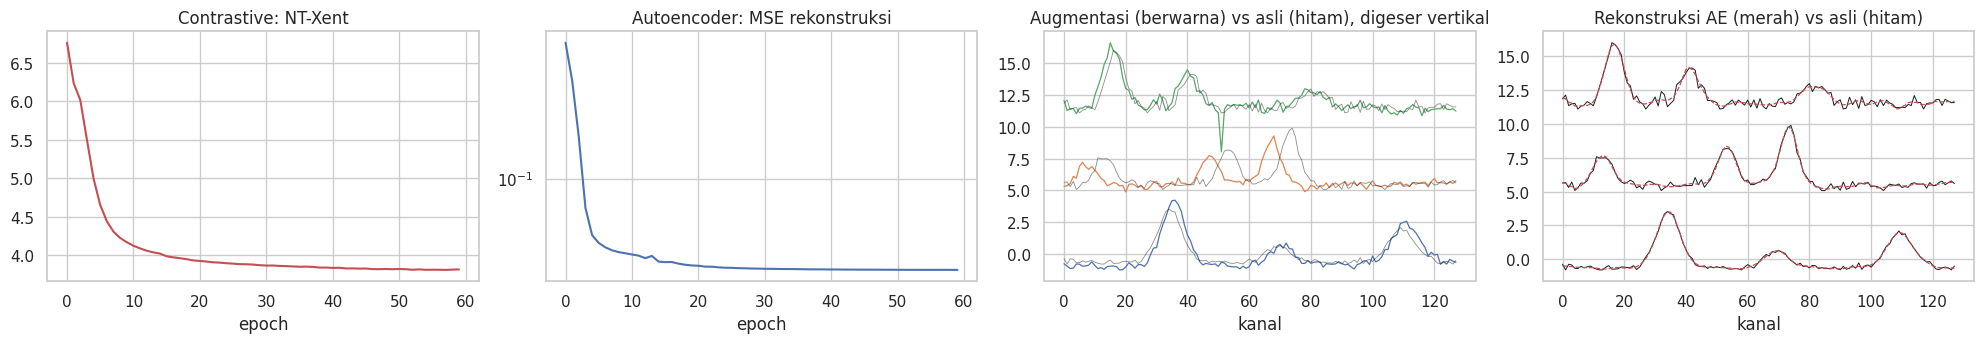

Loss akhir: contrastive = 3.8125 | AE MSE = 0.0243


In [ ]:
# ---- Loss visualization + contoh augmentasi + rekonstruksi AE ----
fig, ax = plt.subplots(1, 4, figsize=(20, 3.6))
ax[0].plot(HIST_CL["loss"], c="#c44e52"); ax[0].set(title="Contrastive: NT-Xent", xlabel="epoch")
ax[1].plot(HIST_AE["loss"], c="#4c72b0"); ax[1].set(title="Autoencoder: MSE rekonstruksi", xlabel="epoch", yscale="log")
for k in range(3): ax[2].plot(AUG_DEMO[k] + 6 * k, lw=.9); ax[2].plot(X_PP[k] + 6 * k, "k", lw=.6, alpha=.5)
ax[2].set(title="Augmentasi (berwarna) vs asli (hitam), digeser vertikal", xlabel="kanal")
for k in range(3): ax[3].plot(X_PP[k] + 6 * k, "k", lw=.7); ax[3].plot(AE_RECON[k] + 6 * k, "r--", lw=.9)
ax[3].set(title="Rekonstruksi AE (merah) vs asli (hitam)", xlabel="kanal")
plt.tight_layout(); plt.show()
print(f"Loss akhir: contrastive = {HIST_CL['loss'][-1]:.4f} | AE MSE = {HIST_AE['loss'][-1]:.4f}")

## 7.x Evaluasi kualitas representasi (tanpa label)
Tiga ukuran yang tidak memerlukan label:
1. **Keterpisahan cluster** pada embedding: silhouette terbaik untuk k=2..8 dan Davies-Bouldin pada k itu.
2. **Kebocoran geseran:** seberapa baik geseran puncak per sampel (`SHIFT`, 5.3) dapat **diprediksi dari embedding** (R² regresi Ridge/kNN dengan validasi silang). Embedding yang baik harus **tidak** menyimpan distorsi, jadi R² harus rendah.
3. **Kestabilan terhadap seed** dinilai di Section 13 untuk clustering akhir.

In [ ]:
def shift_leakage(E, shift, n_sample=8000):
    sub = np.random.default_rng(SEED).choice(len(E), min(n_sample, len(E)), replace=False); Zs = StandardScaler().fit_transform(E[sub]); y = shift[sub]
    p_lin = cross_val_predict(Ridge(1.0), Zs, y, cv=3); p_knn = cross_val_predict(KNeighborsRegressor(15), Zs, y, cv=3)
    return float(r2_score(y, p_lin)), float(r2_score(y, p_knn))

E_PCA = PCA(EMB_DIM, random_state=SEED).fit_transform(X_PP)
SPEC_EMB = {"PCA (baseline)": E_PCA, "Autoencoder": E_AE, "Contrastive (aug. geser)": E_CL}
rows = []
for nm, E in SPEC_EMB.items():
    q = cluster_quality(E); b = q.loc[q["silhouette"].idxmax()]; r2l, r2k = shift_leakage(E, SHIFT)
    rows.append({"representasi": nm, "dim": E.shape[1], "silhouette terbaik": b["silhouette"], "pada k": int(b["k"]), "DB di k itu": b["DB"],
                 "R2 geseran (linear)": r2l, "R2 geseran (kNN)": r2k})
tab_rep = pd.DataFrame(rows); print(tab_rep.round(3).to_string(index=False))
tab_rep.to_csv(OUTPUT_DIR / "evaluasi_representasi_spektrum.csv", index=False)

# Representasi spektrum untuk fusion: pilih dari model deep learning (PCA = pembanding) dengan silhouette terbaik
dl = tab_rep[tab_rep["representasi"] != "PCA (baseline)"]
SPEC_NAME = dl.loc[dl["silhouette terbaik"].idxmax(), "representasi"]; E_SPEC = SPEC_EMB[SPEC_NAME]
print(f"\nRepresentasi spektrum terpilih untuk fusion: {SPEC_NAME} ({E_SPEC.shape})")

            representasi  dim  silhouette terbaik  pada k  DB di k itu  R2 geseran (linear)  R2 geseran (kNN)
          PCA (baseline)   32               0.483       4        0.866                0.703             0.796
             Autoencoder   32               0.473       4        0.868                0.646             0.825
Contrastive (aug. geser)   32               0.445       5        0.964                0.117             0.024

Representasi spektrum terpilih untuk fusion: Autoencoder ((36000, 32))


**Interpretasi.** Kolom *R² geseran* menunjukkan seberapa banyak informasi geseran (distorsi) yang masih tersimpan; **semakin rendah semakin baik**. PCA dan autoencoder dilatih hanya untuk merekonstruksi/menjelaskan varians sehingga
cenderung menyimpan geseran, sedangkan contrastive encoder dilatih dengan augmentasi geser agar tidak peduli terhadapnya. Bandingkan juga *silhouette terbaik*: bila embedding invarian geseran, satu jenis material tidak lagi terbelah menjadi dua,
sehingga cluster lebih padat dan terpisah. Representasi dengan silhouette terbaik di antara model deep learning dipakai pada fusion. Angka persisnya bergantung pada hasil training di Colab, jadi **baca tabel di atas, bukan teks ini**,
dan jika contrastive tidak unggul, laporkan apa adanya (itu juga temuan yang sah).

# SECTION 8 — Multimodal Fusion

Menggabungkan **embedding spektrum** (Section 7) dan **embedding gambar** (Anggota 1, Section 6). Strategi yang dibandingkan:

| Strategi | Cara kerja | Alasan |
|---|---|---|
| **Concat skala-blok** (bobot gambar 0,5 / 1 / 2) | tiap modality dipusatkan dan diskalakan agar norma baris rata-rata = 1, lalu digabung | sederhana; skala-blok mencegah modality berdimensi besar mendominasi hanya karena dimensinya; bobot menguji "seberapa penting gambar" |
| **Concat PCA-whitened** (16 + 16) | tiap modality diputihkan (PCA whiten) ke 16 komponen, lalu digabung | setiap arah variasi bermakna punya bobot setara; meredam arah ber-varians-besar yang hanya noise/domain |
| **CCA** (16 komponen kanonik) | proyeksi ke ruang bersama yang paling berkorelasi antar-modality | menangkap struktur yang **konsisten di kedua modality** dan membuang variasi yang hanya ada di satu sisi (mis. kecerahan mikroskop pada gambar) |

Pemilihan strategi memakai ukuran **tanpa label** (silhouette terbaik/Davies-Bouldin, Section 5.2) pada hasil fusion, dan **tidak** memakai label referensi. Silhouette cenderung menyukai ruang yang didominasi modality yang cluster-nya paling rapat,
jadi hasilnya dibaca bersama analisis "apa yang hilang bila satu modality" (Section 11 dan 13), bukan sebagai kebenaran mutlak.

**Hipotesis yang diuji (bukan fakta):** pada beberapa contoh gambar, satu kelompok spektral tampak memuat **lebih dari satu tekstur gambar** (mis. bercak gelap vs pola labirin). Bila benar, gambar memisahkan jenis material yang spektrumnya tidak bisa membedakan.

In [ ]:
def block_scale(E):
    E = np.asarray(E, np.float64); E = E - E.mean(0)
    return (E / np.sqrt((E ** 2).sum(1).mean())).astype(np.float32)            # norma baris rata-rata = 1 -> sumbangan modality setara

def whiten_pca(E, n=16):
    E = np.asarray(E, np.float64)
    return PCA(min(n, E.shape[1]), whiten=True, random_state=SEED).fit_transform(E - E.mean(0)).astype(np.float32)

def cca_fusion(Es, Ei, n=16):
    A, B = whiten_pca(Es, 32), whiten_pca(Ei, 32)                              # setelah diputihkan, kovarians silang = korelasi kanonik
    U, S, Vt = np.linalg.svd(A.T @ B / len(A), full_matrices=False); n = min(n, len(S))
    return np.hstack([A @ U[:, :n], B @ Vt.T[:, :n]]).astype(np.float32), S[:n]

def knn_overlap(A, B, k=10, n=3000, shuffle=False):
    # Rata-rata irisan k-tetangga terdekat di ruang A vs ruang B untuk sampel yang SAMA. Jika pairing benar, > acak.
    rg = np.random.default_rng(SEED); sub = rg.choice(len(A), n, replace=False); A, B = A[sub], B[sub]
    if shuffle: B = B[rg.permutation(n)]
    nA = NearestNeighbors(n_neighbors=k + 1).fit(A).kneighbors(A, return_distance=False)[:, 1:]
    nB = NearestNeighbors(n_neighbors=k + 1).fit(B).kneighbors(B, return_distance=False)[:, 1:]
    return float(np.mean([len(set(a) & set(b)) / k for a, b in zip(nA, nB)]))

FUSIONS, FUSION_TABLE = {}, None
if not HAS_IMG:
    print("=" * 100); print("FUSION DIHENTIKAN: embedding gambar Anggota 1 belum tersedia (lihat Section 6).")
    print("Section 9 dst. memakai embedding SPEKTRUM saja sebagai mode sementara; hasilnya bukan hasil akhir dan cluster.csv final tidak ditulis.")
    print("=" * 100)
    E_FUSED, FUSION_NAME = E_SPEC, f"(spektrum saja) {SPEC_NAME}"
else:
    # ---- 8.1 Pemeriksaan pairing ID: statistik ----
    assert E_IMG.shape[0] == E_SPEC.shape[0] == N == len(IDS), "jumlah baris berbeda antar-modality"
    Zs, Zi = prep_for_cluster(E_SPEC), prep_for_cluster(E_IMG)
    ov_real, ov_shuf = knn_overlap(Zs, Zi), knn_overlap(Zs, Zi, shuffle=True)
    print(f"Pairing: irisan 10-tetangga spektrum vs gambar = {ov_real:.4f} | kontrol (pairing diacak) = {ov_shuf:.4f} | acak teoritis ~ {10 / 3000:.4f}")
    if ov_real < 2 * ov_shuf:
        print("PERINGATAN: irisan tidak jauh di atas acak. Periksa lagi urutan/ID embedding gambar (mungkin pairing salah) sebelum melanjutkan!")
    else:
        print("OK: tetangga terdekat di kedua modality jauh lebih sering sama daripada acak -> pairing konsisten.")

    # ---- 8.2 Strategi fusion ----
    Bs, Bi = block_scale(E_SPEC), block_scale(E_IMG)
    FUSIONS["Concat skala-blok (w_gambar=0.5)"] = np.hstack([Bs, 0.5 * Bi])
    FUSIONS["Concat skala-blok (w_gambar=1)"] = np.hstack([Bs, Bi])
    FUSIONS["Concat skala-blok (w_gambar=2)"] = np.hstack([Bs, 2.0 * Bi])
    FUSIONS["Concat PCA-whitened (16+16)"] = np.hstack([whiten_pca(E_SPEC, 16), whiten_pca(E_IMG, 16)])
    FUSIONS["CCA (16 komponen)"], cca_corr = cca_fusion(E_SPEC, E_IMG, 16)
    print(f"Korelasi kanonik (5 pertama): {np.round(cca_corr[:5], 3).tolist()}")

    rows = []
    for nm, E in [("Spektrum saja", E_SPEC), ("Gambar saja", E_IMG)] + list(FUSIONS.items()):
        assert E.shape[0] == N and np.isfinite(E).all(), nm
        q = cluster_quality(E); b = q.loc[q["silhouette"].idxmax()]
        rows.append({"representasi": nm, "dim": E.shape[1], "silhouette terbaik": b["silhouette"], "pada k": int(b["k"]), "DB di k itu": b["DB"]})
    FUSION_TABLE = pd.DataFrame(rows); print("\n" + FUSION_TABLE.round(3).to_string(index=False))
    FUSION_TABLE.to_csv(OUTPUT_DIR / "perbandingan_fusion.csv", index=False)

    cand = FUSION_TABLE[FUSION_TABLE["representasi"].isin(FUSIONS)]
    FUSION_NAME = cand.loc[cand["silhouette terbaik"].idxmax(), "representasi"]; E_FUSED = FUSIONS[FUSION_NAME]
    print(f"\nStrategi fusion terpilih: {FUSION_NAME} | dimensi hasil fusion = {E_FUSED.shape} (baris = {N} = jumlah sampel; urutan = urutan meta)")
np.save(OUTPUT_DIR / "emb_fusi.npy", E_FUSED)

FUSION DIHENTIKAN: embedding gambar Anggota 1 belum tersedia (lihat Section 6).
Section 9 dst. memakai embedding SPEKTRUM saja sebagai mode sementara; hasilnya bukan hasil akhir dan cluster.csv final tidak ditulis.


**Interpretasi.** Baca tabel di atas dengan tiga pertanyaan: **(1)** apakah gabungan lebih baik daripada spektrum saja dan gambar saja pada keterpisahan cluster? **(2)** apakah *k terbaik* berubah ketika gambar ditambahkan
(kolom "pada k"; jika naik, gambar membuka pembagian halus yang tidak terlihat di spektrum)? **(3)** apakah bobot gambar yang berbeda mengubah kesimpulan? Pemeriksaan pairing (irisan tetangga vs kontrol acak) memastikan baris spektrum dan gambar
benar-benar berpasangan; bila irisannya tidak jauh di atas acak, **hentikan** dan periksa ID embedding sebelum clustering. Alasan pemilihan strategi terakhir dibahas di Section 14.

# SECTION 9 — Clustering Method 1: KMeans (dan GMM sebagai pembanding)

* **KMeans** (`n_init=10`, jarak Euclid) dan **Gaussian Mixture** (kovarians penuh) pada embedding fusi yang direduksi **PCA 16-d** (`E_CL16`), untuk k = 2…12.
* **Hyperparameter:** `k` adalah satu-satunya hyperparameter utama; ditentukan dengan **aturan agregasi peringkat** atas silhouette, Davies-Bouldin, dan kestabilan (ARI antar-resampling). Calinski-Harabasz dan BIC-GMM dilaporkan sebagai bukti pendukung.
  Pembahasan lengkap kriteria ada di **Section 11**; aturan pemilihannya didefinisikan di sini karena DEC (Section 10) memerlukan `k`.
* **Cluster assignment** untuk semua k disimpan di `OUTPUT_DIR`.

In [ ]:
E_CL16 = prep_for_cluster(E_FUSED)                          # ruang clustering seragam untuk semua metode (PCA 16-d)
print("Ruang clustering:", E_CL16.shape, "| MODE =", MODE)

def internal_metrics(Z, lab, n_sample=8000):
    sub = np.random.default_rng(SEED).choice(len(Z), min(n_sample, len(Z)), replace=False)
    return float(silhouette_score(Z[sub], lab[sub])), float(davies_bouldin_score(Z, lab)), float(calinski_harabasz_score(Z, lab))

def stability_ari(Z, k, n_rep=N_STAB, frac=0.7):
    # Kestabilan: dua KMeans pada subsampel 70% berbeda; label semua titik diprediksi lalu dibandingkan (ARI). 1 = identik.
    rg = np.random.default_rng(SEED); sc = []
    for r in range(n_rep):
        a, b = rg.choice(len(Z), int(frac * len(Z)), replace=False), rg.choice(len(Z), int(frac * len(Z)), replace=False)
        ma = KMeans(k, n_init=3, random_state=SEED + r).fit(Z[a]); mb = KMeans(k, n_init=3, random_state=SEED + 100 + r).fit(Z[b])
        sc.append(adjusted_rand_score(ma.predict(Z), mb.predict(Z)))
    return float(np.mean(sc)), float(np.std(sc))

LABELS_KM, LABELS_GMM, rows = {}, {}, []
t0 = time.time()
for k in K_RANGE:
    km = KMeans(k, n_init=N_INIT, random_state=SEED).fit(E_CL16); LABELS_KM[k] = km.labels_
    gm = GaussianMixture(k, covariance_type="full", n_init=2, random_state=SEED).fit(E_CL16); LABELS_GMM[k] = gm.predict(E_CL16)
    s, db, ch = internal_metrics(E_CL16, km.labels_); st, st_sd = stability_ari(E_CL16, k)
    rows.append({"k": k, "silhouette": s, "DB": db, "CH": ch, "stabilitas_ARI": st, "stab_sd": st_sd, "inertia": km.inertia_,
                 "GMM_BIC": gm.bic(E_CL16), "GMM_silhouette": internal_metrics(E_CL16, LABELS_GMM[k])[0]})
SWEEP = pd.DataFrame(rows).set_index("k"); print(f"Sweep k selesai dalam {time.time() - t0:.0f} dtk"); print(SWEEP.round(3).to_string())
SWEEP.to_csv(OUTPUT_DIR / "sweep_k.csv")

Ruang clustering: (36000, 16) | MODE = spektrum_saja
Sweep k selesai dalam 152 dtk
    silhouette     DB         CH  stabilitas_ARI  stab_sd      inertia      GMM_BIC  GMM_silhouette
k                                                                                                  
2        0.302  1.596  13486.743           0.997    0.002  1982074.008  1384613.939           0.301
3        0.412  1.108  17618.659           0.999    0.001  1376860.149  1158258.013           0.412
4        0.473  0.860  23261.009           0.997    0.002   927187.285   983412.094           0.466
5        0.439  0.905  21800.545           0.909    0.117   796075.842   935024.804           0.417
6        0.413  0.952  21803.935           0.903    0.105   676293.769   899112.894           0.421
7        0.397  0.971  23151.952           0.820    0.102   560700.007   868422.147           0.345
8        0.404  0.913  24710.974           0.925    0.124   469287.095   861869.757           0.397
9        0.385  0

In [ ]:
def select_k(sweep):
    # Agregasi peringkat: peringkat tiap kriteria (1 = terbaik) dirata-rata; k dengan rata-rata terkecil menang; seri -> k lebih kecil (parsimoni)
    crit = {"silhouette": (sweep["silhouette"], True), "DB": (sweep["DB"], False), "stabilitas_ARI": (sweep["stabilitas_ARI"], True)}
    ranks = pd.DataFrame({n: v.rank(ascending=not hi, method="min") for n, (v, hi) in crit.items()})
    mean_rank = ranks.mean(1); return int(mean_rank.idxmin()), ranks, mean_rank

K_SEL, RANKS, MEAN_RANK = select_k(SWEEP)
PICKS = {"silhouette (maks)": int(SWEEP["silhouette"].idxmax()), "Davies-Bouldin (min)": int(SWEEP["DB"].idxmin()),
         "stabilitas ARI (maks)": int(SWEEP["stabilitas_ARI"].idxmax()), "Calinski-Harabasz (maks)": int(SWEEP["CH"].idxmax()), "BIC GMM (min)": int(SWEEP["GMM_BIC"].idxmin())}
print("k pilihan tiap kriteria:", PICKS); print("Rata-rata peringkat (silhouette, DB, stabilitas):"); print(MEAN_RANK.round(2).to_dict())
print(f"\n>>> K_SEL = {K_SEL}")

labels_km, labels_gmm = LABELS_KM[K_SEL], LABELS_GMM[K_SEL]
np.savez(OUTPUT_DIR / "assign_kmeans_gmm.npz", ids=IDS, k_values=np.array(K_RANGE),
         **{f"km_k{k}": LABELS_KM[k] for k in K_RANGE}, **{f"gmm_k{k}": LABELS_GMM[k] for k in K_RANGE})
print(f"KMeans (k={K_SEL}) ukuran cluster:", np.bincount(labels_km).tolist()); print(f"GMM    (k={K_SEL}) ukuran cluster:", np.bincount(labels_gmm, minlength=K_SEL).tolist())

k pilihan tiap kriteria: {'silhouette (maks)': 4, 'Davies-Bouldin (min)': 4, 'stabilitas ARI (maks)': 3, 'Calinski-Harabasz (maks)': 8, 'BIC GMM (min)': 12}
Rata-rata peringkat (silhouette, DB, stabilitas):
{2: 8.33, 3: 5.0, 4: 1.33, 5: 3.0, 6: 5.67, 7: 8.33, 8: 4.0, 9: 7.33, 10: 7.0, 11: 7.67, 12: 8.33}

>>> K_SEL = 4
KMeans (k=4) ukuran cluster: [8682, 8590, 10022, 8706]
GMM    (k=4) ukuran cluster: [10037, 8663, 8680, 8620]


# SECTION 10 — Clustering Method 2: Deep Embedded Clustering (DEC)

**Arsitektur.** Autoencoder MLP pada embedding fusi (distandardisasi): encoder `D → 256 → 128 → 10` dan decoder simetris. Lapisan tambahan berupa **pusat cluster** `μ_j ∈ R^10` (parameter yang dapat dilatih), j = 1…k.

**Tahap 1 — pra-latih** autoencoder dengan MSE rekonstruksi. **Tahap 2 — inisialisasi** `μ_j` dengan KMeans pada latent. **Tahap 3 — DEC:**

* **Soft assignment (Student-t):** `q_ij = (1 + ||z_i − μ_j||²)^−1 / Σ_j' (1 + ||z_i − μ_j'||²)^−1`
* **Target distribution (mempertajam):** `p_ij = (q_ij² / f_j) / Σ_j' (q_ij'² / f_j')`, dengan `f_j = Σ_i q_ij` (normalisasi frekuensi cluster agar cluster besar tidak mendominasi)
* **Fungsi tujuan:** `L = KL(P ‖ Q) + γ · MSE(x, x̂)`, `γ = 0,1`. Suku KL menarik titik ke cluster yang sudah paling yakin ditempati; suku rekonstruksi (varian IDEC) menjaga latent tidak rusak.
* `P` dihitung ulang pada **awal tiap epoch** (seluruh data), pelatihan memakai **mini-batch** 1.024 dan Adam. **Berhenti** bila persentase label yang berubah antar-epoch < 0,1%.

`k` memakai `K_SEL` dari Section 9. Embedding, bobot, dan assignment disimpan agar tidak perlu melatih ulang.

In [ ]:
import hashlib

class DECNet(nn.Module):
    def __init__(self, in_dim, k, hid=(256, 128), lat=DEC_LATENT):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(in_dim, hid[0]), nn.ReLU(), nn.Linear(hid[0], hid[1]), nn.ReLU(), nn.Linear(hid[1], lat))
        self.dec = nn.Sequential(nn.Linear(lat, hid[1]), nn.ReLU(), nn.Linear(hid[1], hid[0]), nn.ReLU(), nn.Linear(hid[0], in_dim))
        self.centers = nn.Parameter(torch.zeros(k, lat))
    def soft_assign(self, z, alpha=1.0):
        d2 = torch.cdist(z, self.centers) ** 2; q = (1.0 + d2 / alpha) ** (-(alpha + 1.0) / 2.0)
        return q / q.sum(1, keepdim=True)

def target_distribution(q):
    w = q ** 2 / q.sum(0, keepdim=True); return w / w.sum(1, keepdim=True)

def run_dec(E, k, bs=1024):
    Xs = StandardScaler().fit_transform(E).astype(np.float32); X = torch.from_numpy(Xs).to(DEVICE); n, d = X.shape
    net = DECNet(d, k).to(DEVICE); hist = {"pretrain_loss": [], "dec_loss": [], "delta": []}
    # ---- Tahap 1: pra-latih autoencoder ----
    opt = torch.optim.Adam(list(net.enc.parameters()) + list(net.dec.parameters()), lr=1e-3)
    for ep in range(DEC_PRETRAIN_EPOCHS):
        net.train(); perm = torch.randperm(n, device=DEVICE); run = 0.0; nb = max(n // bs, 1)
        for i in range(nb):
            xb = X[perm[i * bs:(i + 1) * bs]]; loss = F.mse_loss(net.dec(net.enc(xb)), xb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); run += loss.item()
        hist["pretrain_loss"].append(run / nb)
        if ep == 0 or (ep + 1) % 20 == 0: print(f"[DEC pra-latih] epoch {ep + 1:03d}/{DEC_PRETRAIN_EPOCHS} | MSE = {run / nb:.4f}")
    # ---- Tahap 2: inisialisasi pusat dengan KMeans pada latent ----
    net.eval()
    with torch.no_grad(): Z0 = net.enc(X).cpu().numpy()
    km = KMeans(k, n_init=20, random_state=SEED).fit(Z0); net.centers.data = torch.from_numpy(km.cluster_centers_.astype(np.float32)).to(DEVICE); prev = km.labels_
    # ---- Tahap 3: DEC ----
    opt = torch.optim.Adam(net.parameters(), lr=DEC_LR)
    for ep in range(DEC_EPOCHS):
        net.eval()
        with torch.no_grad(): Q = net.soft_assign(net.enc(X)); P = target_distribution(Q)
        lab = Q.argmax(1).cpu().numpy(); delta = float((lab != prev).mean()); prev = lab; hist["delta"].append(delta)
        if ep >= 5 and delta < DEC_TOL:
            print(f"[DEC] berhenti di epoch {ep}: label berubah {delta * 100:.3f}% < {DEC_TOL * 100:.1f}%"); break
        net.train(); perm = torch.randperm(n, device=DEVICE); run = 0.0; nb = max(n // bs, 1)
        for i in range(nb):
            idx = perm[i * bs:(i + 1) * bs]; xb = X[idx]; z = net.enc(xb); q = net.soft_assign(z)
            loss = F.kl_div(q.clamp_min(1e-8).log(), P[idx], reduction="batchmean") + DEC_GAMMA * F.mse_loss(net.dec(z), xb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); run += loss.item()
        hist["dec_loss"].append(run / nb)
        if ep == 0 or (ep + 1) % 10 == 0: print(f"[DEC] epoch {ep + 1:03d} | loss = {run / nb:.4f} | label berubah = {delta * 100:.2f}%")
    net.eval()
    with torch.no_grad(): Zf = net.enc(X); labels = net.soft_assign(Zf).argmax(1).cpu().numpy(); Zf = Zf.cpu().numpy()
    return net, hist, labels, Zf

def run_dec_cached(E, k):
    tag = f"dec_{MODE}_k{k}_{hashlib.md5(np.ascontiguousarray(E, dtype=np.float32).tobytes()).hexdigest()[:8]}"     # cache dikunci ke isi embedding
    f = OUTPUT_DIR / f"{tag}.npz"
    if f.exists() and not RETRAIN:
        z = np.load(f, allow_pickle=False); print(f"[DEC] dimuat dari cache {f}"); return z["labels"], z["Z"], json.loads(str(z["hist"]))
    net, hist, labels, Z = run_dec(E, k); torch.save(net.state_dict(), OUTPUT_DIR / f"{tag}.pt")
    np.savez(f, labels=labels, Z=Z, hist=json.dumps(hist)); return labels, Z, hist

In [ ]:
# [TORCH-RUN] DEC: latih Deep Embedded Clustering pada embedding fusi (atau muat dari cache)
set_seed(); LABELS_DEC, Z_DEC, HIST_DEC = run_dec_cached(E_FUSED, K_SEL)
np.save(OUTPUT_DIR / "assign_dec.npy", LABELS_DEC)
print(f"DEC (k={K_SEL}) ukuran cluster:", np.bincount(LABELS_DEC, minlength=K_SEL).tolist(), "| dimensi latent:", Z_DEC.shape)

[DEC pra-latih] epoch 001/60 | MSE = 0.5591
[DEC pra-latih] epoch 020/60 | MSE = 0.0263
[DEC pra-latih] epoch 040/60 | MSE = 0.0232
[DEC pra-latih] epoch 060/60 | MSE = 0.0222
[DEC] epoch 001 | loss = 0.0575 | label berubah = 0.00%
[DEC] berhenti di epoch 5: label berubah 0.003% < 0.1%
DEC (k=4) ukuran cluster: [10044, 8642, 8632, 8682] | dimensi latent: (36000, 10)


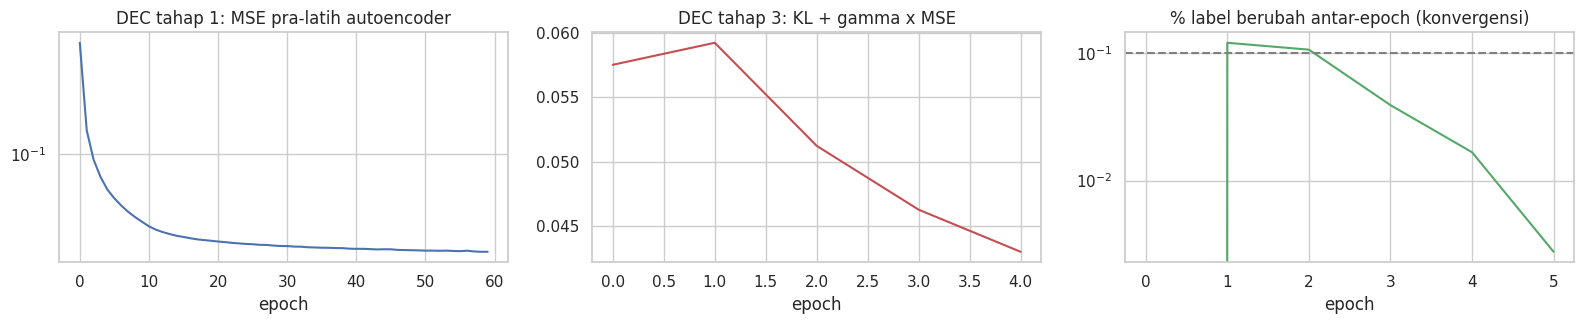

ARI DEC vs KMeans (k=4): 0.927 | vs GMM: 0.998


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
ax[0].plot(HIST_DEC["pretrain_loss"]); ax[0].set(title="DEC tahap 1: MSE pra-latih autoencoder", xlabel="epoch", yscale="log")
ax[1].plot(HIST_DEC["dec_loss"], c="#c44e52"); ax[1].set(title="DEC tahap 3: KL + gamma x MSE", xlabel="epoch")
ax[2].plot(np.array(HIST_DEC["delta"]) * 100, c="#55a868"); ax[2].axhline(DEC_TOL * 100, ls="--", c="gray"); ax[2].set(title="% label berubah antar-epoch (konvergensi)", xlabel="epoch", yscale="log")
plt.tight_layout(); plt.show()
print(f"ARI DEC vs KMeans (k={K_SEL}): {adjusted_rand_score(LABELS_DEC, labels_km):.3f} | vs GMM: {adjusted_rand_score(LABELS_DEC, labels_gmm):.3f}")

**Interpretasi.** Loss KL turun dan persentase label yang berubah mendekati nol menandakan DEC konvergen ke partisi yang stabil. Perbandingan ARI antara DEC dan KMeans/GMM menunjukkan seberapa jauh pelatihan mendalam
**mengubah** partisi dibanding clustering klasik pada ruang yang sama; ARI mendekati 1 berarti DEC hanya mempertajam partisi yang sudah ada, nilai rendah berarti DEC menemukan struktur berbeda (nilai persisnya dibahas di Section 13–14).

# SECTION 11 — Number of Clusters Selection

Syarat: **minimal dua kriteria**. Yang dipakai: **Silhouette**, **Davies-Bouldin**, **Calinski-Harabasz**, **BIC (GMM)**, dan **kestabilan ARI** antar-resampling (partisi yang benar harus muncul ulang pada subsampel berbeda).
Keputusan akhir memakai agregasi peringkat atas tiga kriteria yang tidak monoton terhadap k (silhouette, Davies-Bouldin, kestabilan; Section 9).
Calinski-Harabasz dan BIC dilaporkan sebagai pendukung karena cenderung terus membaik pada k besar (BIC untuk 36.000 sampel hampir selalu menyukai lebih banyak komponen).

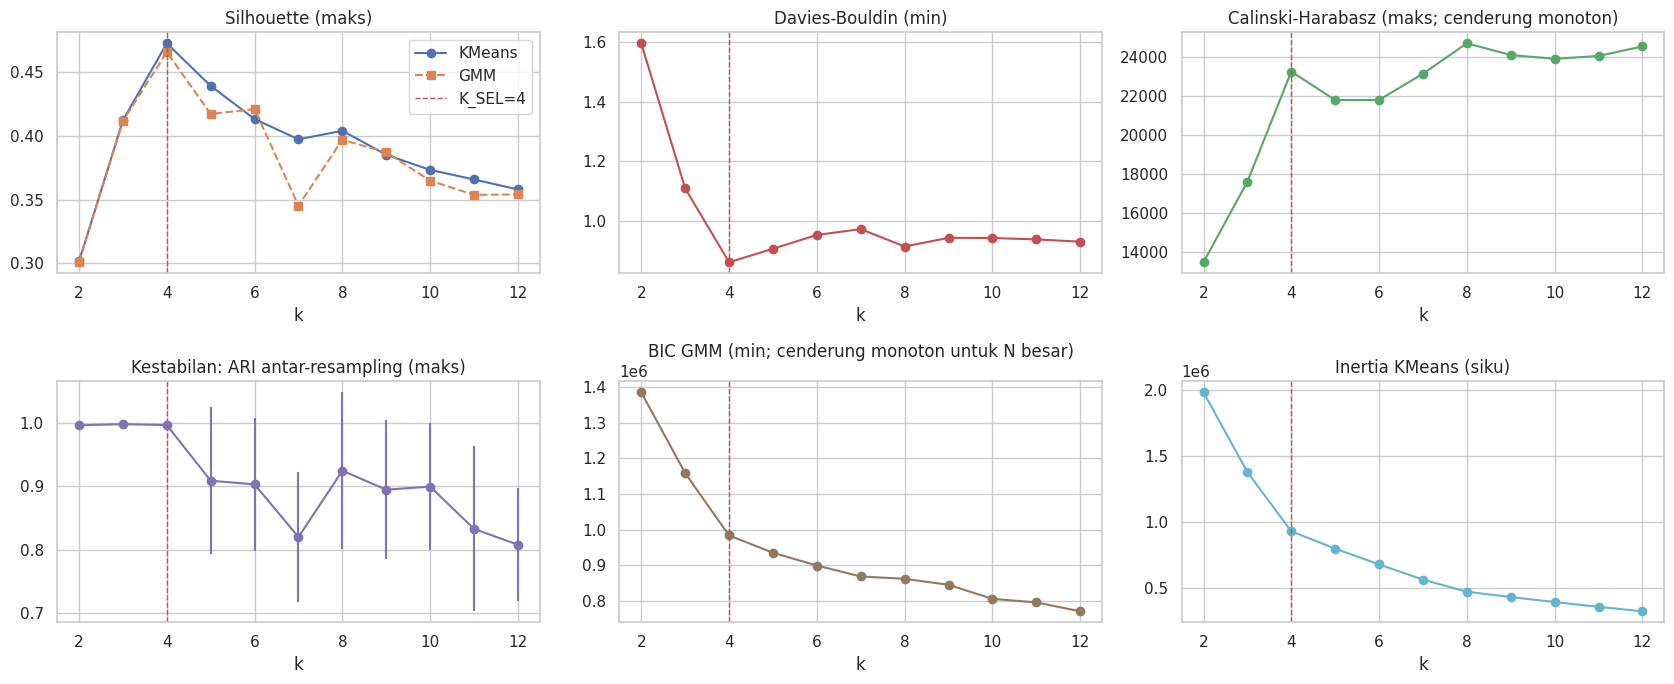

            silhouette (maks)  Davies-Bouldin (min)  stabilitas ARI (maks)  Calinski-Harabasz (maks)  BIC GMM (min)
k terpilih                  4                     4                      3                         8             12
Rata-rata peringkat tiap k (kecil = baik): {2: 8.33, 3: 5.0, 4: 1.33, 5: 3.0, 6: 5.67, 7: 8.33, 8: 4.0, 9: 7.33, 10: 7.0, 11: 7.67, 12: 8.33}
=> K_SEL = 4


In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(17, 7)); ks = SWEEP.index.values
def mark(a): a.axvline(K_SEL, c="r", ls="--", lw=1, label=f"K_SEL={K_SEL}")
ax[0, 0].plot(ks, SWEEP["silhouette"], "o-", label="KMeans"); ax[0, 0].plot(ks, SWEEP["GMM_silhouette"], "s--", label="GMM"); mark(ax[0, 0]); ax[0, 0].set(title="Silhouette (maks)", xlabel="k"); ax[0, 0].legend()
ax[0, 1].plot(ks, SWEEP["DB"], "o-", c="#c44e52"); mark(ax[0, 1]); ax[0, 1].set(title="Davies-Bouldin (min)", xlabel="k")
ax[0, 2].plot(ks, SWEEP["CH"], "o-", c="#55a868"); mark(ax[0, 2]); ax[0, 2].set(title="Calinski-Harabasz (maks; cenderung monoton)", xlabel="k")
ax[1, 0].errorbar(ks, SWEEP["stabilitas_ARI"], yerr=SWEEP["stab_sd"], fmt="o-", c="#8172b2"); mark(ax[1, 0]); ax[1, 0].set(title="Kestabilan: ARI antar-resampling (maks)", xlabel="k")
ax[1, 1].plot(ks, SWEEP["GMM_BIC"], "o-", c="#937860"); mark(ax[1, 1]); ax[1, 1].set(title="BIC GMM (min; cenderung monoton untuk N besar)", xlabel="k")
ax[1, 2].plot(ks, SWEEP["inertia"], "o-", c="#64b5cd"); mark(ax[1, 2]); ax[1, 2].set(title="Inertia KMeans (siku)", xlabel="k")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"k terpilih": PICKS}).T.to_string()); print("Rata-rata peringkat tiap k (kecil = baik):", MEAN_RANK.round(2).to_dict()); print(f"=> K_SEL = {K_SEL}")

In [ ]:
# k terbaik menurut tiap modality: apa yang berubah ketika modality ditambahkan/dibuang?
mod_sets = {"Spektrum saja": E_SPEC}
if HAS_IMG: mod_sets.update({"Gambar saja": E_IMG, f"Fusi ({FUSION_NAME})": E_FUSED})
rows = []
for nm, E in mod_sets.items():
    q = cluster_quality(E, ks=range(2, 10)); rows.append({"modality": nm, "k terbaik (silhouette)": int(q.loc[q['silhouette'].idxmax(), 'k']), "silhouette": q['silhouette'].max(),
                                                          "k terbaik (DB)": int(q.loc[q['DB'].idxmin(), 'k']), "DB": q['DB'].min()})
MOD_PICKS = pd.DataFrame(rows); print(MOD_PICKS.round(3).to_string(index=False))
if not HAS_IMG: print("\n(Perbandingan gambar-saja/fusi menunggu embedding gambar Anggota 1.)")

     modality  k terbaik (silhouette)  silhouette  k terbaik (DB)    DB
Spektrum saja                       4       0.473               4 0.868

(Perbandingan gambar-saja/fusi menunggu embedding gambar Anggota 1.)


**Interpretasi.** Kriteria yang berbeda memang boleh memilih k yang berbeda; itu bukan kesalahan, melainkan tanda **struktur hierarkis** (kelompok kasar yang terbagi lagi menjadi kelompok halus). Silhouette dan Davies-Bouldin biasanya menyukai partisi **kasar** yang paling rapat,
sedangkan Calinski-Harabasz, BIC, dan inertia mendorong ke k yang lebih besar. Karena itu keputusan memakai gabungan peringkat dengan **kestabilan** sebagai penyeimbang: partisi halus yang tidak muncul ulang pada subsampel berbeda
(mis. pembagian yang hanya mengikuti geseran puncak spektrum, Section 5.3) mendapat kestabilan rendah dan tidak dipilih. Tabel "k terbaik menurut modality" memperlihatkan **apa yang hilang bila satu modality dipakai**: bila k terbaik pada fusi
lebih besar daripada pada spektrum saja, gambar membuka pembagian jenis material yang tidak terlihat dari spektrum.

# SECTION 12 — Visualization

UMAP (seluruh 36.000 sampel) dan t-SNE (subsampel 6.000, karena t-SNE jauh lebih lambat) pada ruang clustering yang sama (`E_CL16`). Dibandingkan: KMeans, GMM, DEC, serta pewarnaan menurut **mikroskop** (untuk memeriksa pengaruh domain shift).

UMAP selesai 109 dtk
t-SNE selesai 53 dtk


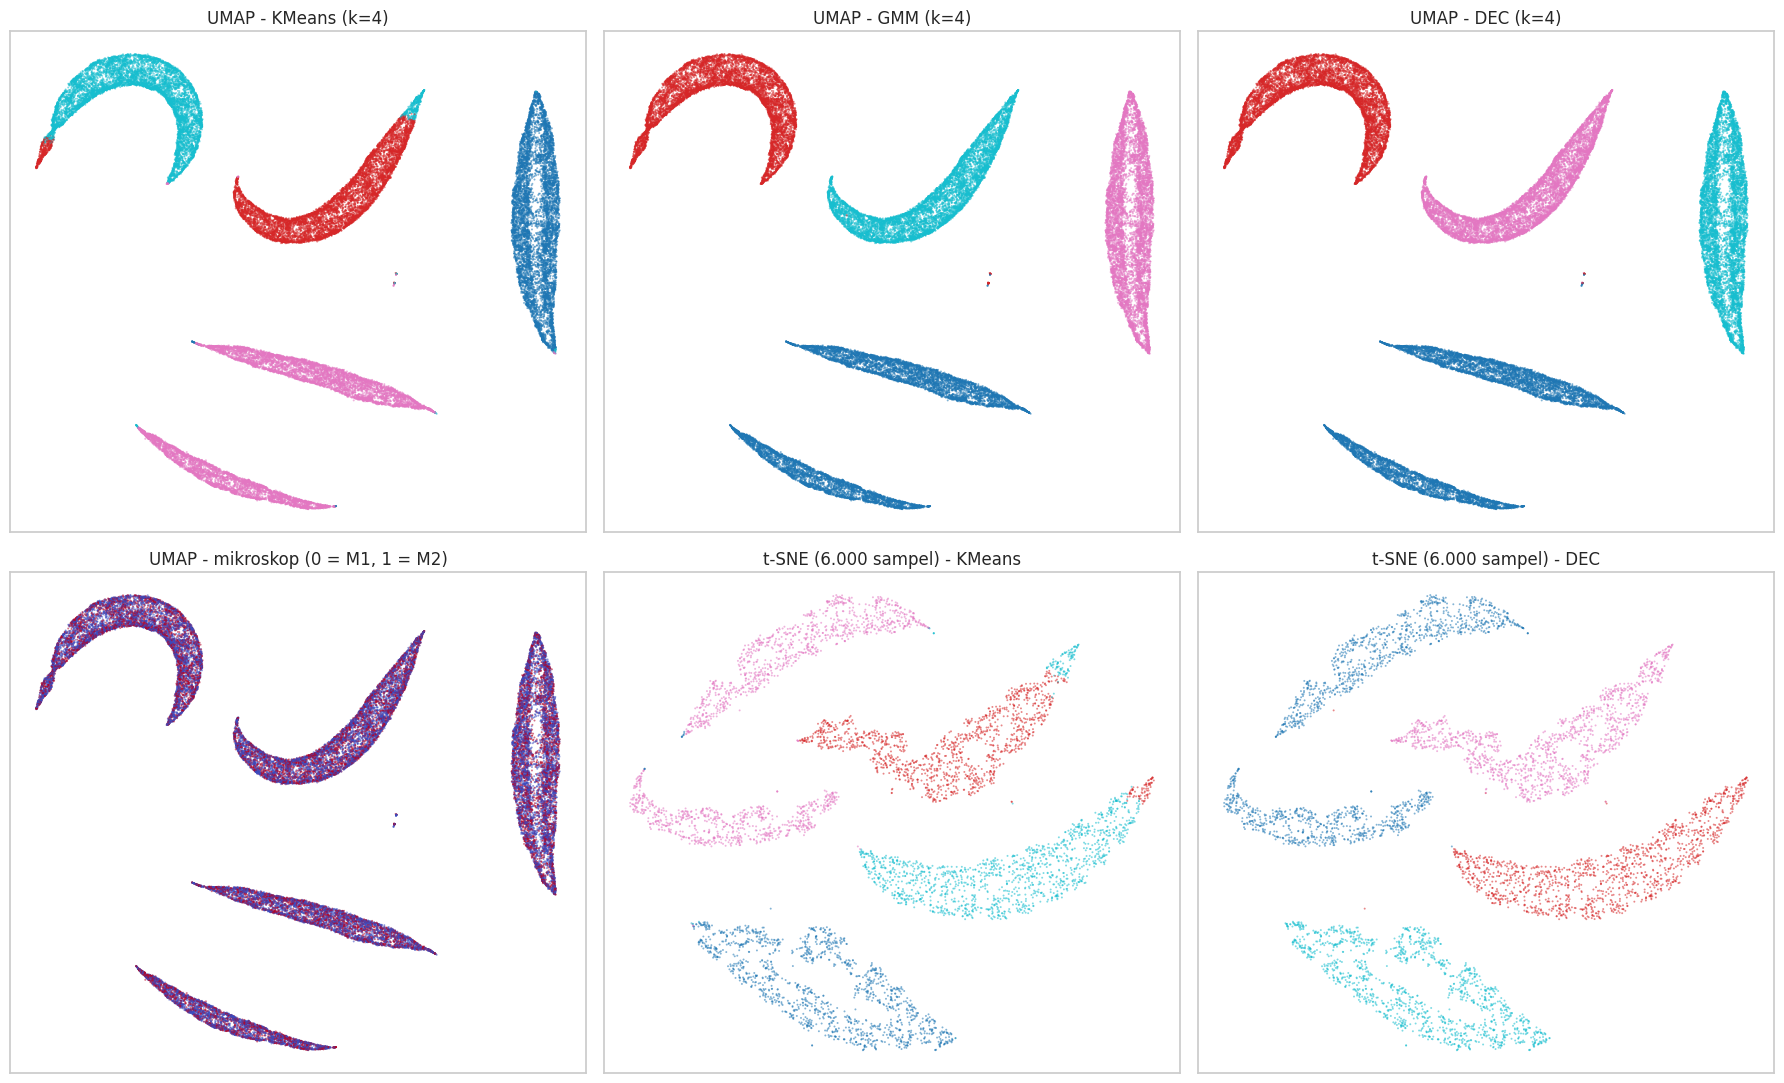

In [ ]:
t0 = time.time(); UMAP_XY = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(E_CL16); print(f"UMAP selesai {time.time() - t0:.0f} dtk")
TS_IDX = np.random.default_rng(SEED).choice(N, 6000, replace=False); t0 = time.time()
TSNE_XY = TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(E_CL16[TS_IDX]); print(f"t-SNE selesai {time.time() - t0:.0f} dtk")
np.save(OUTPUT_DIR / "umap_xy.npy", UMAP_XY); np.save(OUTPUT_DIR / "tsne_xy.npy", TSNE_XY)

def scatter(ax, xy, lab, title, cmap=None):
    cm = cmap or ("tab10" if len(np.unique(lab)) <= 10 else "tab20"); ax.scatter(xy[:, 0], xy[:, 1], c=lab, cmap=cm, s=2, alpha=.55, linewidths=0)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(2, 3, figsize=(18, 11))
scatter(ax[0, 0], UMAP_XY, labels_km, f"UMAP - KMeans (k={K_SEL})"); scatter(ax[0, 1], UMAP_XY, labels_gmm, f"UMAP - GMM (k={K_SEL})"); scatter(ax[0, 2], UMAP_XY, LABELS_DEC, f"UMAP - DEC (k={K_SEL})")
scatter(ax[1, 0], UMAP_XY, MIC, "UMAP - mikroskop (0 = M1, 1 = M2)", cmap="coolwarm")
scatter(ax[1, 1], TSNE_XY, labels_km[TS_IDX], "t-SNE (6.000 sampel) - KMeans"); scatter(ax[1, 2], TSNE_XY, LABELS_DEC[TS_IDX], "t-SNE (6.000 sampel) - DEC")
plt.tight_layout(); plt.show()

 cluster     n  silhouette rata2  % titik batas (sil < 0.1)  cluster tetangga terdekat  jarak ke tetangga
       0  8682             0.506                      1.546                          2             11.470
       1  8590             0.454                      4.000                          3             10.213
       2 10022             0.480                      1.250                          1             11.186
       3  8706             0.450                      5.710                          1             10.213

Pasangan cluster paling berdekatan: 1 dan 3 (jarak pusat = 10.213); cluster paling tidak terpisah: 3


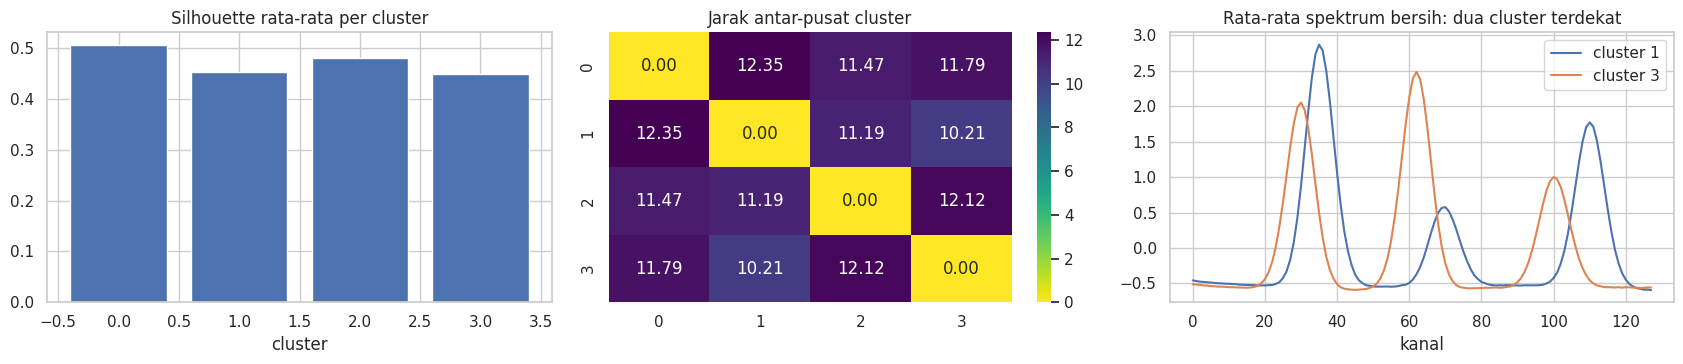

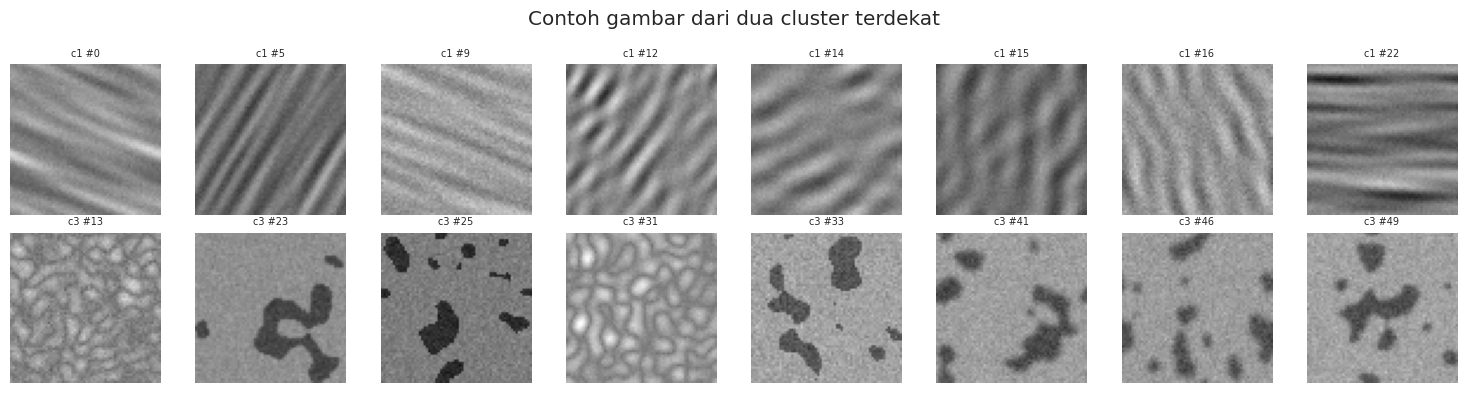

In [ ]:
# ---- Cluster yang sulit dipisahkan (berdasarkan KMeans) ----
sub = np.random.default_rng(SEED).choice(N, 8000, replace=False); sil_i = silhouette_samples(E_CL16[sub], labels_km[sub]); lab_sub = labels_km[sub]
per_cl = pd.DataFrame({"cluster": range(K_SEL), "n": np.bincount(labels_km, minlength=K_SEL),
                       "silhouette rata2": [sil_i[lab_sub == c].mean() for c in range(K_SEL)],
                       "% titik batas (sil < 0.1)": [(sil_i[lab_sub == c] < 0.1).mean() * 100 for c in range(K_SEL)]})
CEN = np.stack([E_CL16[labels_km == c].mean(0) for c in range(K_SEL)])
DM = np.linalg.norm(CEN[:, None] - CEN[None], axis=2); np.fill_diagonal(DM, np.inf); a, b = np.unravel_index(np.argmin(DM), DM.shape)
per_cl["cluster tetangga terdekat"] = DM.argmin(1); per_cl["jarak ke tetangga"] = DM.min(1); print(per_cl.round(3).to_string(index=False))
print(f"\nPasangan cluster paling berdekatan: {a} dan {b} (jarak pusat = {DM[a, b]:.3f}); cluster paling tidak terpisah: {int(per_cl.loc[per_cl['silhouette rata2'].idxmin(), 'cluster'])}")

fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
ax[0].bar(per_cl["cluster"], per_cl["silhouette rata2"], color="#4c72b0"); ax[0].axhline(0, c="k", lw=.6); ax[0].set(title="Silhouette rata-rata per cluster", xlabel="cluster")
D_show = DM.copy(); np.fill_diagonal(D_show, 0); sns.heatmap(D_show, annot=K_SEL <= 8, fmt=".2f", cmap="viridis_r", ax=ax[1]); ax[1].set_title("Jarak antar-pusat cluster")
for c in (a, b): ax[2].plot(X_PP[labels_km == c].mean(0), label=f"cluster {c}")
ax[2].set(title="Rata-rata spektrum bersih: dua cluster terdekat", xlabel="kanal"); ax[2].legend()
plt.tight_layout(); plt.show()
if HAS_IMAGES:
    fig, ax = plt.subplots(2, 8, figsize=(15, 4))
    for r, c in enumerate((a, b)):
        for j, i in enumerate(np.where(labels_km == c)[0][:8]): ax[r, j].imshow(GAMBAR[i], cmap="gray", vmin=0, vmax=255); ax[r, j].axis("off"); ax[r, j].set_title(f"c{c} #{i}", fontsize=7)
    plt.suptitle("Contoh gambar dari dua cluster terdekat"); plt.tight_layout(); plt.show()

**Analisis cluster yang sulit dipisahkan.** Cluster yang sulit dipisahkan terlihat dari tiga petunjuk yang konsisten: **(1)** silhouette rata-rata rendah dan persentase titik batas tinggi, **(2)** pusat cluster saling berdekatan (heatmap jarak), dan **(3)** wilayah yang bertumpuk di UMAP/t-SNE.
Untuk pasangan terdekat, perhatikan **rata-rata spektrum** dan **contoh gambar** kedua cluster: bila spektrumnya hampir sama dan gambarnya yang berbeda (atau sebaliknya), pasangan itu hanya terpisah oleh **satu modality**, dan gangguan pada modality tersebut
(noise spektrum, geseran puncak, perbedaan kecerahan antar-mikroskop) langsung menimbulkan tumpang tindih. Jika pewarnaan menurut mikroskop memperlihatkan pola yang sejalan dengan cluster, itu tanda *domain shift*, bukan jenis material. Pengukurannya ada di Section 13.

# SECTION 13 — Cluster Evaluation

**ARI terhadap label referensi.** Sesuai ketentuan, label jenis material sebenarnya **tidak dibagikan**; ARI resmi dihitung dosen dari `cluster.csv`. Label referensi **tidak pernah** dipakai untuk training atau fitting di notebook ini.
Fungsi `ari_vs_reference` di bawah baru aktif bila berkas `referensi_label.csv` (kolom `id_sampel`, `label`) kebetulan tersedia, misalnya untuk simulasi internal; tanpa berkas itu, evaluasi memakai **ukuran pengganti yang sah tanpa label**:
metrik internal, **kesepakatan antar-metode (ARI)**, **kestabilan antar-seed**, **keterkaitan dengan mikroskop** (kontrol domain shift), dan **nilai tiap modality**.

In [ ]:
def find_ref():
    for d in [DATA_DIR, OUTPUT_DIR, Path(".")]:
        if (Path(d) / REF_LABEL_FILE).exists(): return Path(d) / REF_LABEL_FILE
    return None

def ari_vs_reference(labels_dict):
    p = find_ref()
    if p is None:
        print(f"Label referensi ({REF_LABEL_FILE}) tidak tersedia -> ARI terhadap jenis material sebenarnya TIDAK dapat dihitung di sini (dihitung dosen)."); return None
    ref = pd.read_csv(p).set_index("id_sampel")["label"].reindex(IDS)
    assert ref.notna().all(), "label referensi tidak lengkap untuk semua id_sampel"
    return {nm: adjusted_rand_score(ref.to_numpy(), lab) for nm, lab in labels_dict.items()}      # hanya EVALUASI

METHODS = {"KMeans": labels_km, "GMM": labels_gmm, "DEC": LABELS_DEC}
print("ARI vs referensi:", ari_vs_reference(METHODS))

# ---- 13.1 Metrik internal (ruang yang sama) + keterkaitan dengan mikroskop ----
def micro_assoc(lab):
    ct = pd.crosstab(lab, MIC); chi2, p, _, _ = chi2_contingency(ct)
    return float(normalized_mutual_info_score(lab, MIC)), float(p), (ct[1] / ct.sum(1)).round(3).to_dict()

rows = []
for nm, lab in METHODS.items():
    s, db, ch = internal_metrics(E_CL16, lab); nmi_m, p_m, frac = micro_assoc(lab)
    rows.append({"metode": nm, "k": len(np.unique(lab)), "silhouette": s, "DB": db, "CH": ch, "NMI vs mikroskop": nmi_m, "p chi2 mikroskop": p_m})
EVAL = pd.DataFrame(rows).set_index("metode"); print(EVAL.round(4).to_string())
print(f"\nFraksi M2 per cluster (KMeans) - fraksi global M2 = {MIC.mean():.3f}:", micro_assoc(labels_km)[2])

Label referensi (referensi_label.csv) tidak tersedia -> ARI terhadap jenis material sebenarnya TIDAK dapat dihitung di sini (dihitung dosen).
ARI vs referensi: None
        k  silhouette      DB          CH  NMI vs mikroskop  p chi2 mikroskop
metode                                                                       
KMeans  4      0.4728  0.8598  23261.0092               0.0            0.4864
GMM     4      0.4659  0.8887  22188.0214               0.0            0.3557
DEC     4      0.4662  0.8878  22243.6783               0.0            0.3839

Fraksi M2 per cluster (KMeans) - fraksi global M2 = 0.399: {0: 0.392, 1: 0.401, 2: 0.4, 3: 0.403}


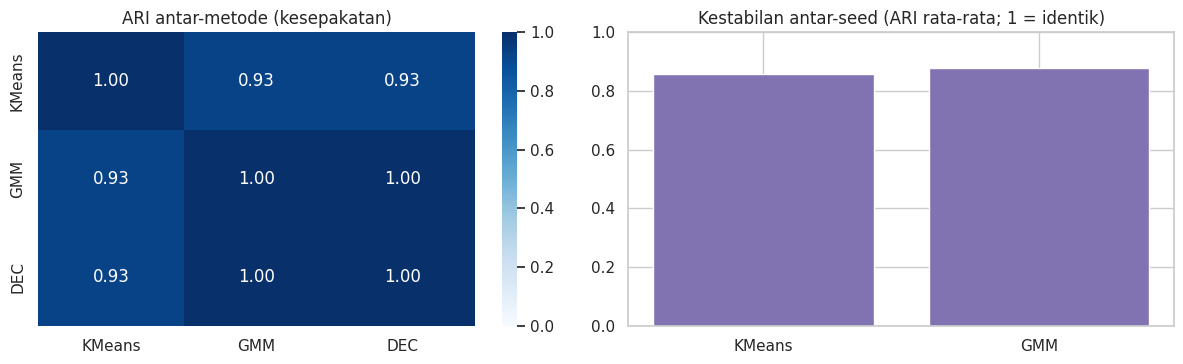

        k  silhouette      DB          CH  NMI vs mikroskop  p chi2 mikroskop  stabilitas antar-seed (ARI)
metode                                                                                                    
KMeans  4      0.4728  0.8598  23261.0092               0.0            0.4864                       0.8579
GMM     4      0.4659  0.8887  22188.0214               0.0            0.3557                       0.8771
DEC     4      0.4662  0.8878  22243.6783               0.0            0.3839                          NaN


In [ ]:
# ---- 13.2 Kesepakatan antar-metode dan kestabilan antar-seed ----
names = list(METHODS); AG = pd.DataFrame([[adjusted_rand_score(METHODS[a], METHODS[b]) for b in names] for a in names], index=names, columns=names)
def seed_stability(fit_predict, n=N_STAB):
    L_ = [fit_predict(SEED + 10 * s) for s in range(n)]; return float(np.mean([adjusted_rand_score(L_[i], L_[j]) for i in range(n) for j in range(i + 1, n)]))
STAB_SEED = {"KMeans": seed_stability(lambda s: KMeans(K_SEL, n_init=1, random_state=s).fit_predict(E_CL16)),
             "GMM": seed_stability(lambda s: GaussianMixture(K_SEL, covariance_type="full", n_init=1, random_state=s).fit_predict(E_CL16))}
EVAL["stabilitas antar-seed (ARI)"] = pd.Series(STAB_SEED)          # DEC: 1 kali latih (biaya); cukup dilihat dari konvergensi + ARI vs KMeans
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); sns.heatmap(AG, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax[0]); ax[0].set_title("ARI antar-metode (kesepakatan)")
ax[1].bar(list(STAB_SEED), list(STAB_SEED.values()), color="#8172b2"); ax[1].set(title="Kestabilan antar-seed (ARI rata-rata; 1 = identik)", ylim=(0, 1)); plt.tight_layout(); plt.show()
print(EVAL.round(4).to_string())

In [ ]:
# ---- 13.3 Nilai tiap modality: apa yang hilang bila hanya satu modality? ----
if not HAS_IMG:
    print("Perbandingan modality DITUNDA: embedding gambar belum tersedia (Section 6).")
    MODALITY_CMP = None
else:
    lab_spec = KMeans(K_SEL, n_init=N_INIT, random_state=SEED).fit_predict(prep_for_cluster(E_SPEC))
    lab_img = KMeans(K_SEL, n_init=N_INIT, random_state=SEED).fit_predict(prep_for_cluster(E_IMG))
    ref_lab = labels_km
    MODALITY_CMP = pd.DataFrame({"ARI vs fusi (KMeans)": [adjusted_rand_score(lab_spec, ref_lab), adjusted_rand_score(lab_img, ref_lab)],
                                 "NMI vs fusi": [normalized_mutual_info_score(lab_spec, ref_lab), normalized_mutual_info_score(lab_img, ref_lab)],
                                 "NMI vs mikroskop": [normalized_mutual_info_score(lab_spec, MIC), normalized_mutual_info_score(lab_img, MIC)],
                                 "silhouette (ruang modality)": [internal_metrics(prep_for_cluster(E_SPEC), lab_spec)[0], internal_metrics(prep_for_cluster(E_IMG), lab_img)[0]]},
                                index=["Spektrum saja", "Gambar saja"])
    print(MODALITY_CMP.round(3).to_string()); print(f"ARI spektrum-saja vs gambar-saja = {adjusted_rand_score(lab_spec, lab_img):.3f}")
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
    for a_, (x, y, tt) in zip(ax, [(lab_spec, ref_lab, "spektrum-saja (baris) vs fusi (kolom)"), (lab_img, ref_lab, "gambar-saja (baris) vs fusi (kolom)"), (lab_spec, lab_img, "spektrum-saja (baris) vs gambar-saja (kolom)")]):
        sns.heatmap(pd.crosstab(x, y), annot=K_SEL <= 8, fmt="d", cmap="Blues", ax=a_); a_.set_title(tt)
    plt.tight_layout(); plt.show()

Perbandingan modality DITUNDA: embedding gambar belum tersedia (Section 6).


**Interpretasi.** **(1)** *Kesepakatan antar-metode* yang tinggi berarti struktur cluster kokoh terhadap pilihan algoritma; yang rendah menunjukkan wilayah ambigu. **(2)** *Kestabilan antar-seed* mendekati 1 berarti hasil tidak bergantung pada inisialisasi acak. **(3)** *NMI terhadap mikroskop*
yang kecil (dan fraksi M2 per cluster mendekati fraksi global) berarti cluster **tidak** mengikuti mikroskop; nilai besar menandakan domain shift bocor ke cluster. **(4)** Pada **crosstab modality**, sel yang tersebar (bukan satu sel dominan per baris/kolom) menunjukkan bahwa kedua modality
**membagi sampel dengan cara berbeda**: itulah informasi yang hilang bila hanya satu modality dipakai. Karena label referensi tidak tersedia, semua ini adalah **bukti tidak langsung**; ARI sebenarnya ditentukan dosen.

# SECTION 14 — Final Analysis

Metode terbaik dipilih dengan **agregasi peringkat** atas ukuran tanpa-label pada ruang yang sama: silhouette (↑), Davies-Bouldin (↓), keterkaitan dengan mikroskop (↓, domain shift), dan kestabilan antar-seed (↑, hanya untuk metode yang diulang).
**Catatan bias:** semua ukuran dihitung pada `E_CL16`, ruang tempat KMeans mengoptimalkan jaraknya, sehingga KMeans cenderung diuntungkan pada silhouette/DB; DEC belajar di latent-nya sendiri. Karena itu pilihan ini adalah keputusan terbaik **yang tersedia tanpa label**, bukan bukti keunggulan mutlak.

In [ ]:
R_ = pd.DataFrame({"silhouette": EVAL["silhouette"].rank(ascending=False), "DB": EVAL["DB"].rank(ascending=True),
                   "mikroskop": EVAL["NMI vs mikroskop"].rank(ascending=True), "stabilitas": EVAL["stabilitas antar-seed (ARI)"].rank(ascending=False)})
EVAL["rata-rata peringkat"] = R_.mean(1, skipna=True)
BEST_METHOD = EVAL["rata-rata peringkat"].idxmin(); FINAL_LABELS = METHODS[BEST_METHOD].astype(int)
print(EVAL.round(4).to_string()); print(f"\nMetode terbaik (agregasi peringkat tanpa label): {BEST_METHOD} | k = {K_SEL} | mode = {MODE}")
EVAL.to_csv(OUTPUT_DIR / "evaluasi_akhir.csv"); np.save(OUTPUT_DIR / "assign_final.npy", FINAL_LABELS)

        k  silhouette      DB          CH  NMI vs mikroskop  p chi2 mikroskop  stabilitas antar-seed (ARI)  rata-rata peringkat
metode                                                                                                                         
KMeans  4      0.4728  0.8598  23261.0092               0.0            0.4864                       0.8579                 1.25
GMM     4      0.4659  0.8887  22188.0214               0.0            0.3557                       0.8771                 2.50
DEC     4      0.4662  0.8878  22243.6783               0.0            0.3839                          NaN                 2.00

Metode terbaik (agregasi peringkat tanpa label): KMeans | k = 4 | mode = spektrum_saja


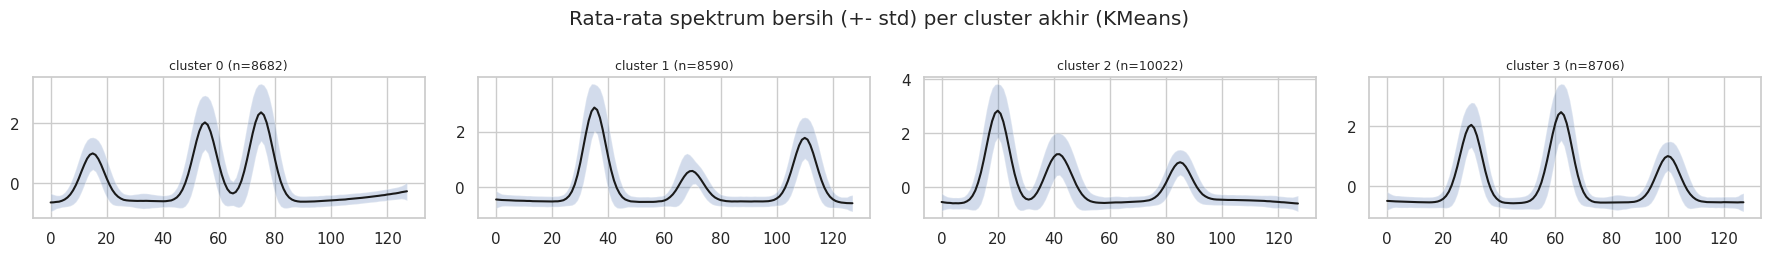

 cluster     n  % sampel posisi puncak (kanal)                           tinggi puncak  % M2  std geseran puncak
       0  8682     24.12              [55, 75] [2.009999990463257, 2.3499999046325684] 39.21                2.53
       1  8590     23.86             [35, 110] [2.869999885559082, 1.7699999809265137] 40.12                2.20
       2 10022     27.84                  [20]                    [2.8399999141693115] 39.99                2.49
       3  8706     24.18              [30, 62] [2.049999952316284, 2.4800000190734863] 40.27                2.43


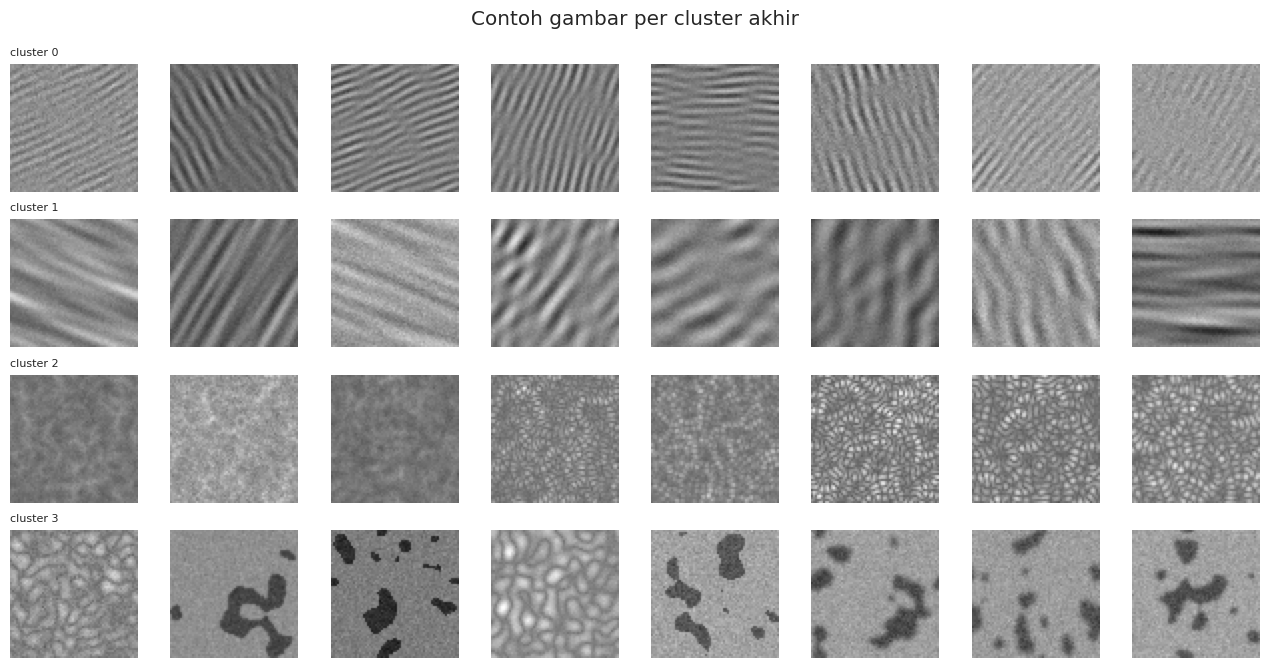

In [ ]:
# ---- Karakteristik cluster akhir ----
rows = []; fig, ax = plt.subplots(int(np.ceil(K_SEL / 4)), 4, figsize=(18, 2.6 * int(np.ceil(K_SEL / 4))), squeeze=False)
for c in range(K_SEL):
    m = FINAL_LABELS == c; mean_sp = X_PP[m].mean(0); sd_sp = X_PP[m].std(0); pk, _ = find_peaks(mean_sp, height=0.5 * mean_sp.max(), distance=6)
    a_ = ax[c // 4, c % 4]; a_.plot(mean_sp, "k"); a_.fill_between(np.arange(L), mean_sp - sd_sp, mean_sp + sd_sp, alpha=.25); a_.set_title(f"cluster {c} (n={int(m.sum())})", fontsize=9)
    rows.append({"cluster": c, "n": int(m.sum()), "% sampel": m.mean() * 100, "posisi puncak (kanal)": pk.tolist(), "tinggi puncak": mean_sp[pk].round(2).tolist(), "% M2": MIC[m].mean() * 100,
                 "std geseran puncak": float(SHIFT[m].std())})
for j in range(K_SEL, ax.size): ax.ravel()[j].axis("off")
plt.suptitle(f"Rata-rata spektrum bersih (+- std) per cluster akhir ({BEST_METHOD})"); plt.tight_layout(); plt.show()
CHAR = pd.DataFrame(rows); print(CHAR.round(2).to_string(index=False)); CHAR.to_csv(OUTPUT_DIR / "karakteristik_cluster.csv", index=False)

if HAS_IMAGES:
    fig, ax = plt.subplots(K_SEL, 8, figsize=(13, 1.7 * K_SEL), squeeze=False)
    for c in range(K_SEL):
        for j, i in enumerate(np.where(FINAL_LABELS == c)[0][:8]): ax[c, j].imshow(GAMBAR[i], cmap="gray", vmin=0, vmax=255); ax[c, j].axis("off")
        ax[c, 0].set_title(f"cluster {c}", fontsize=8, loc="left")
    plt.suptitle("Contoh gambar per cluster akhir"); plt.tight_layout(); plt.show()

## Analisis dan keterbatasan
* **Karakteristik cluster.** Tabel dan grafik di atas merinci tiap cluster: ukuran, **posisi dan tinggi puncak spektrum** (penanda komposisi), proporsi mikroskop, dan contoh gambar. Cluster yang puncaknya identik tetapi gambarnya berbeda menunjukkan jenis material yang hanya dibedakan oleh gambar, dan sebaliknya.
* **Keterbatasan eksperimen.**
  1. **Tidak ada label** di tangan mahasiswa: pemilihan k, representasi, fusion, dan metode terbaik memakai ukuran internal/kestabilan, yang bisa berbeda dari ARI sebenarnya (terutama bila jenis material berbagi spektrum atau gambar).
  2. **Jumlah cluster** pada data hierarkis ambigu; silhouette cenderung memilih partisi kasar. Kestabilan membantu tetapi tidak menjamin k yang sesuai dengan jenis material sesungguhnya.
  3. **Ukuran internal dihitung di ruang `E_CL16`** (PCA 16-d), yang menguntungkan KMeans; DEC dan GMM tidak sepenuhnya dinilai secara adil.
  4. **Geseran puncak** diestimasi dengan heuristik per kelompok spektral (hanya sebagai diagnostik) dan tidak sempurna.
  5. **Satu run** untuk representasi deep learning dan DEC (biaya waktu); variasi antar-seed hanya diukur untuk KMeans/GMM.
  6. **Domain shift mikroskop** ditangani oleh image embedding Anggota 1; di sini hanya **diukur** (NMI/chi²), tidak dikoreksi.

# SECTION 15 — Export CSV

Berkas `cluster.csv` dengan kolom **`id_sampel, cluster`** (satu baris per sampel, `cluster` bilangan bulat), sesuai ketentuan. Nomor cluster boleh bebas karena penilaian memakai ARI.
Pada **mode `spektrum_saja`** (embedding gambar belum tersedia) berkas **tidak** diberi nama `cluster.csv`, supaya hasil sementara tidak terkirim sebagai hasil akhir.

In [ ]:
EXPORT_NAME = str((Path("..") if Path.cwd().name == "kode" else Path(".")) / ("cluster.csv" if MODE == "multimodal" else "cluster_spektrum_saja_SEMENTARA.csv"))   # di root repo
submission = pd.DataFrame({"id_sampel": IDS, "cluster": FINAL_LABELS.astype(int)})
submission.to_csv(EXPORT_NAME, index=False)

# ---- Validasi format ----
chk = pd.read_csv(EXPORT_NAME)
assert list(chk.columns) == ["id_sampel", "cluster"], chk.columns.tolist()
assert len(chk) == N == len(meta), f"jumlah baris {len(chk)} != {N}"
assert chk["id_sampel"].is_unique and set(chk["id_sampel"]) == set(meta["id_sampel"]) and (chk["id_sampel"].to_numpy() == IDS).all()
assert pd.api.types.is_integer_dtype(chk["cluster"]) and not chk.isna().any().any()
print(f"Tersimpan: {Path(EXPORT_NAME).resolve()} | {len(chk)} baris | {chk['cluster'].nunique()} cluster | ukuran: {chk['cluster'].value_counts().sort_index().to_dict()}")
print("Baris pertama:", chk.iloc[0].tolist(), "(format: S123456,4)"); print(chk.head())
if MODE != "multimodal":
    print("\n" + "=" * 100); print("PERINGATAN: ini hasil SEMENTARA dari spektrum saja (embedding gambar tidak tersedia). JANGAN dikumpulkan sebagai cluster.csv."); print("=" * 100)
print(f"\nBerkas {EXPORT_NAME} ada di folder notebook; salinan beserta embedding/bobot model ada di {OUTPUT_DIR.resolve()}")

Tersimpan: /content/cluster_spektrum_saja_SEMENTARA.csv | 36000 baris | 4 cluster | ukuran: {0: 8682, 1: 8590, 2: 10022, 3: 8706}
Baris pertama: ['S966119', np.int64(1)] (format: S123456,4)
  id_sampel  cluster
0   S966119        1
1   S315633        0
2   S805122        2
3   S467543        0
4   S475842        0

PERINGATAN: ini hasil SEMENTARA dari spektrum saja (embedding gambar Anggota 1 belum ada). JANGAN dikumpulkan sebagai cluster.csv.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# SECTION 16 — Conclusion

In [ ]:
print(f"Mode                    : {MODE}")
print(f"Representasi spektrum   : {SPEC_NAME}")
print(f"Strategi fusion         : {FUSION_NAME}")
print(f"Jumlah cluster (K_SEL)  : {K_SEL}  | pilihan per kriteria: {PICKS}")
print(f"Metode terbaik          : {BEST_METHOD}")
print(EVAL.loc[BEST_METHOD, ["silhouette", "DB", "NMI vs mikroskop"]].round(3).to_dict())
print("Berkas keluaran         :", EXPORT_NAME, "(+ embedding, bobot, assignment di", OUTPUT_DIR, ")")

Mode                    : spektrum_saja
Representasi spektrum   : Autoencoder
Strategi fusion         : (spektrum saja) Autoencoder
Jumlah cluster (K_SEL)  : 4  | pilihan per kriteria: {'silhouette (maks)': 4, 'Davies-Bouldin (min)': 4, 'stabilitas ARI (maks)': 3, 'Calinski-Harabasz (maks)': 8, 'BIC GMM (min)': 12}
Metode terbaik          : KMeans
{'silhouette': 0.473, 'DB': 0.86, 'NMI vs mikroskop': 0.0}
Berkas keluaran         : cluster_spektrum_saja_SEMENTARA.csv (+ embedding, bobot, assignment di outputs )


## Kesimpulan

**Temuan dari data spektrum (terverifikasi pada EDA, berlaku untuk dataset yang dibagikan):**
1. Spektrum mentah **didominasi baseline**: komponen utama pertama (±46% varians) berkorelasi ±0,99 dengan rata-rata sampel, jadi clustering langsung pada data mentah mengelompokkan menurut offset, bukan material.
2. Distorsi spektrum ada empat: **baseline** (polinomial halus), **spike** satu kanal (±seperlima sampel), **noise**, dan **geseran puncak kontinu** (std ±2 kanal, rentang ±5 kanal). Mikroskop **tidak** memengaruhi spektrum.
3. Setelah despike (selisih ke tetangga, ambang di jurang antara noise dan spike) dan koreksi baseline (polinomial dengan pemotongan iteratif), keterpisahan cluster naik tanpa label apa pun. Spektrum bersih membentuk **kelompok spektral yang jelas dengan pola puncak berbeda**.
4. Geseran puncak adalah **distorsi, bukan kelas**: ia kontinu dan unimodal di dalam tiap kelompok. Representasi yang menyimpannya (PCA, autoencoder) memecah satu material menjadi beberapa cluster; **contrastive encoder dengan augmentasi geser** dirancang untuk mengabaikannya (R² geseran pada Section 7.x).

**Metode dan jumlah cluster.** Jumlah cluster dipilih dengan **silhouette, Davies-Bouldin, dan kestabilan resampling** (didukung Calinski-Harabasz dan BIC), bukan dengan satu kriteria; clustering memakai **KMeans, GMM, dan DEC** pada embedding fusi spektrum + gambar. Hasil akhir (metode terbaik, k, metrik) tercetak di cell di atas dari run terakhir.

**Insight multimodal.** Nilai penambahan gambar dibaca dari: k terbaik dan silhouette fusi vs modality tunggal (Section 8 dan 11), serta crosstab spektrum-saja vs gambar-saja (Section 13). Bila gambar memisahkan sampel yang spektrumnya mirip, itulah informasi yang hilang pada pendekatan satu modality.

**Kelebihan.** Preprocessing per sampel tanpa label dan tanpa statistik global (tanpa kebocoran); augmentasi yang meniru distorsi nyata; pemilihan k berlapis dan terukur; pemeriksaan pairing ID dan domain shift mikroskop; embedding, bobot, dan assignment tersimpan sehingga tidak perlu training ulang; mode sementara yang tidak menulis `cluster.csv` final tanpa embedding gambar.

**Keterbatasan.** Tidak ada label, jadi ARI sebenarnya tidak dapat diperiksa; pemilihan k pada struktur hierarkis ambigu; satu run untuk model deep learning; ukuran internal dihitung pada ruang PCA 16-d yang menguntungkan KMeans; kualitas hasil akhir sangat bergantung pada **image embedding Anggota 1** (termasuk penanganan perbedaan mikroskop).

**Langkah lanjutan.** Beberapa seed dan ensemble clustering (consensus); fusion terlatih ujung-ke-ujung (loss kontrastif lintas-modality); koreksi domain shift mikroskop pada gambar; tuning `SHIFT_MAX`, `EMB_DIM`, dan bobot fusion dengan kestabilan sebagai panduan.